# Tour 2 — H4 : apprendre sur plusieurs phases du marché (modèle pont)

**Question** : apprendre sur la période longue (prix 2017 à 2023) réduit-il le biais de 2024 et rend-il les variables de territoire plus utiles ?

**Protocole** (feuille de route, tour 2)
- Grille de quatre modèles : « prix N-1 seul » et « prix N-1 + variables de territoire retenues » (modèle complet du niveau 1), chacun appris sur 2020- puis sur la période longue 2017-.
- Mêmes territoires, mêmes années jugées (2023 lue à part, puis 2024), même réglage : Elastic Net sur le log du prix, mêmes grilles, plis temporels.
- On regarde la MAE, l'erreur moyenne signée (le biais) et le coefficient du prix N-1 (plus proche de 1 attendu).
- Le test 2025 n'est pas ouvert : il est réservé au modèle retenu à la fin du niveau 2.

**Comment lire ce notebook** : chaque graphique est suivi d'une lecture dont les chiffres sont calculés par le code (ils suivent les tableaux). Le notebook répond dans l'ordre à : *que prévoit le modèle* (4.1, 4.2), *bat-il la naïve* (4.3), *d'où vient l'erreur* (4.4, 4.5), *combien d'années faut-il* (4.6), *sait-il classer les territoires* (4.7), *quand marche-t-il* (4.8), *où marche-t-il* (4.9), *que pèsent les variables* (4.10), *que vaut l'erreur en pratique* (4.11).

## 1. Import et chargement

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import commun
from commun import CIBLE, charger_table, fenetres, plis_temporels, evaluer, tester

warnings.filterwarnings("ignore")      # convergence de l'Elastic Net sur les plis les plus petits
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
BLEU, ORANGE, GRIS = "#1f4e79", "#d9822b", "#8c8c8c"

# Variables retenues au niveau 1 (modèle complet de H3 globale)
PARC = ["taux_vacance", "part_rsec", "part_apparts", "log_nb_logements", "part_moins40m2",
        "part_avant1946", "part_2006_2019", "anciennete_moyenne", "part_sans_voiture"]
VACANCE = ["taux_vacance_complete"]
DENSITE = ["densite_population"]
REFERENCE_VARS = ["prix_n1"]
MODELE_COMPLET = REFERENCE_VARS + PARC + VACANCE + DENSITE
LOG = ["densite_population", "part_sans_voiture", "part_moins40m2", "part_rsec", "part_apparts", "prix_n1"]
GRILLE_EN = {"alpha": list(np.logspace(-5, -1, 9)), "l1_ratio": [0.2, 0.5, 0.8]}

MODELES = {"prix N-1 seul": REFERENCE_VARS, "prix N-1 + territoire": MODELE_COMPLET}
DEBUTS = [2017, 2018, 2019, 2020, 2021]    # 2017 : période longue ; 2020 : apprentissage actuel ; le reste : sensibilité
ANNEES = [2023, 2024]
TYPES = ["appartement", "maison"]
SCEN = [("prix N-1 seul", 2020), ("prix N-1 seul", 2017), ("prix N-1 + territoire", 2020), ("prix N-1 + territoire", 2017)]
LAB4 = ["N-1 seul\n2020-", "N-1 seul\n2017-", "+ territoire\n2020-", "+ territoire\n2017-"]
LAB5 = ["Naïve"] + [l.replace("+ territoire", "+ terr.") for l in LAB4]
COL4 = [GRIS, BLEU, GRIS, BLEU]
HAT4 = ["", "", "//", "//"]
table = charger_table()
print("Table :", table.shape, "| années", table["annee"].min(), "à", table["annee"].max())


def fr(x, n=1, signe=False):
    """Nombre au format français (virgule, vrai signe moins)."""
    t = f"{x:+.{n}f}" if signe else f"{x:.{n}f}"
    return t.replace(".", ",").replace("-", "−")


def lecture(texte):
    """Affiche une lecture : le texte est construit à partir des tableaux, ses chiffres ne peuvent pas s'en écarter."""
    display(Markdown("**Lecture.** " + texte))

Table : (23489, 39) | années 2017 à 2025


## 2. Constat rapide : ce que la période longue ajoute

Le niveau 1 apprenait sur 2020-2022 (pour juger 2023) et 2020-2023 (pour juger 2024) : une période de forte hausse. La période longue ajoute 2017, 2018 et 2019. Le graphique montre l'évolution annuelle du prix médian au m² (prix de l'année / prix de l'année précédente) par sous-bassin, pour chaque phase du marché.

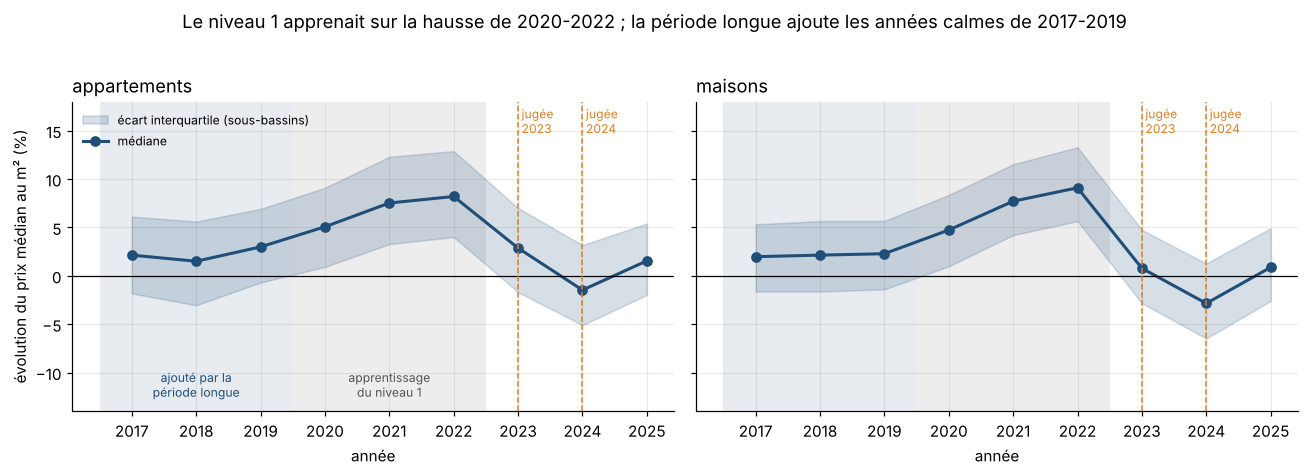

annee,2017,2018,2019,2020,2021,2022,2023,2024,2025
type_bien,,,,,,,,,
appartement,2.1,1.5,3.0,5.1,7.5,8.2,2.9,-1.5,1.5
maison,2.0,2.1,2.3,4.7,7.7,9.1,0.8,-2.9,0.9


In [2]:
# type_bien est dans l'index de la table, annee dans une colonne
evolution = (table[CIBLE] / table["prix_n1"] - 1) * 100
phases = evolution.groupby([table.index.get_level_values("type_bien"), table["annee"].to_numpy()]).describe(percentiles=[.25, .5, .75])
phases.index.names = ["type_bien", "annee"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, tb in zip(axes, TYPES):
    d = phases.loc[tb]
    ax.axvspan(2016.5, 2019.5, color=BLEU, alpha=0.10, lw=0)
    ax.axvspan(2019.5, 2022.5, color=GRIS, alpha=0.15, lw=0)
    ax.fill_between(d.index, d["25%"], d["75%"], color=BLEU, alpha=0.18, label="écart interquartile (sous-bassins)")
    ax.plot(d.index, d["50%"], color=BLEU, marker="o", lw=2, label="médiane")
    ax.axhline(0, color="black", lw=0.8)
    for a in ANNEES:
        ax.axvline(a, color=ORANGE, ls="--", lw=1)
        ax.text(a, 17.5, f" jugée\n {a}", color=ORANGE, fontsize=8, va="top")
    ax.set_title(f"{tb}s", loc="left")
    ax.set_xlabel("année")
    ax.set_xticks(range(2017, 2026))
    ax.set_ylim(-14, 18)
axes[0].set_ylabel("évolution du prix médian au m² (%)")
axes[0].text(2018, -12.5, "ajouté par la\npériode longue", ha="center", fontsize=8, color=BLEU)
axes[0].text(2021, -12.5, "apprentissage\ndu niveau 1", ha="center", fontsize=8, color="#555")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Le niveau 1 apprenait sur la hausse de 2020-2022 ; la période longue ajoute les années calmes de 2017-2019", y=1.02)
fig.tight_layout()
plt.show()
med = phases["50%"].unstack()
med.round(1)

In [3]:
a_, m_ = med.loc["appartement"], med.loc["maison"]
ph, pl = [2020, 2021, 2022], [2017, 2018, 2019]
lecture(f"Le niveau 1 n'a vu que des années en hausse forte : médiane de {fr(a_.loc[ph].min())} à {fr(a_.loc[ph].max())} % par an pour les appartements, "
        f"de {fr(m_.loc[ph].min())} à {fr(m_.loc[ph].max())} % pour les maisons (2020-2022). La période longue ajoute trois années autour de "
        f"{fr(a_.loc[pl].mean())} % (appartements) et {fr(m_.loc[pl].mean())} % (maisons). Les deux années jugées sortent de ce que le niveau 1 avait vu : "
        f"2023 ({fr(a_[2023], signe=True)} % et {fr(m_[2023], signe=True)} %) puis 2024 ({fr(a_[2024], signe=True)} % et {fr(m_[2024], signe=True)} %). "
        "Les bandes interquartiles montrent que les sous-bassins s'écartent de la médiane de plusieurs points chaque année : c'est la part « où », celle que les variables de territoire doivent expliquer.")

**Lecture.** Le niveau 1 n'a vu que des années en hausse forte : médiane de 5,1 à 8,2 % par an pour les appartements, de 4,7 à 9,1 % pour les maisons (2020-2022). La période longue ajoute trois années autour de 2,2 % (appartements) et 2,1 % (maisons). Les deux années jugées sortent de ce que le niveau 1 avait vu : 2023 (+2,9 % et +0,8 %) puis 2024 (−1,5 % et −2,9 %). Les bandes interquartiles montrent que les sous-bassins s'écartent de la médiane de plusieurs points chaque année : c'est la part « où », celle que les variables de territoire doivent expliquer.

## 3. Modèles

Un Elastic Net par type de bien et par fenêtre, sur le log du prix (variables asymétriques en log), réglé sur les plis temporels de la fenêtre. Avec la période longue, la fenêtre compte plus d'années donc plus de plis de réglage : c'est inévitable et identique pour les deux modèles. La naïve (prix N-1 reconduit) est évaluée par `evaluer` sur les mêmes lignes. On garde les prévisions et les coefficients de chaque modèle pour les comparer entre eux.

In [4]:
def en_log(X):
    """Variables asymétriques en log (toutes strictement positives, vérifié)."""
    X = X.copy()
    cols = [c for c in LOG if c in X.columns]
    assert (X[cols] > 0).all().all()
    X[cols] = np.log(X[cols])
    return X


def ajuster(app_t, ev_t, variables):
    """Elastic Net réglé par plis temporels ; renvoie la prévision (€/m²), les coefficients standardisés et le réglage."""
    pipe = Pipeline([("echelle", StandardScaler()), ("modele", ElasticNet(max_iter=50_000))])
    m = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    m = GridSearchCV(m, {"regressor__modele__" + k: v for k, v in GRILLE_EN.items()},
                     cv=plis_temporels(app_t), scoring="neg_mean_absolute_error")
    m.fit(en_log(app_t[variables]), app_t[CIBLE])
    pipe_f = m.best_estimator_.regressor_
    coefs = pd.Series(pipe_f["modele"].coef_, index=variables)
    echelle_n1 = pipe_f["echelle"].scale_[variables.index("prix_n1")]
    return (pd.Series(m.predict(en_log(ev_t[variables])), index=ev_t.index), coefs,
            coefs["prix_n1"] / echelle_n1, {k.split("__")[-1]: v for k, v in m.best_params_.items()})


def pente_mco(app_t):
    """Pente MCO de log(prix) sur log(prix N-1), sans pénalisation : le coefficient lu dans la feuille de route."""
    return LinearRegression().fit(np.log(app_t[["prix_n1"]]), np.log(app_t[CIBLE])).coef_[0]


previsions, resultats, tests, reglages, coefs_std = {}, [], [], [], {}
for debut in DEBUTS:
    F = fenetres(table, annees_jugees=ANNEES, annee_debut=debut)
    for modele, variables in MODELES.items():
        nom = f"{modele} | {debut}-"
        for annee, (app, ev) in F.items():
            prevision = pd.Series(np.nan, index=ev.index)
            for tb, e in app.groupby("type_bien"):
                idx = ev.index[ev.index.get_level_values("type_bien") == tb]
                p, cs, coef, params = ajuster(e, ev.loc[idx], variables)
                prevision.loc[idx] = p
                coefs_std[(modele, debut, annee, tb)] = cs
                reglages.append({"modèle": modele, "début": debut, "année jugée": annee, "type de bien": tb,
                                 "coef. prix N-1": coef, "pente MCO": pente_mco(e) if modele == "prix N-1 seul" else np.nan,
                                 "alpha": params["alpha"], "l1_ratio": params["l1_ratio"], "lignes d'apprentissage": len(e)})
            previsions[(modele, debut, annee)] = prevision
            if debut in (2017, 2020):                 # tests complets pour les deux périodes de la grille
                evaluer(nom, ev, prevision, resultats)
                tester(nom, ev, prevision, tests)
reglages = pd.DataFrame(reglages)
print(len(previsions), "séries de prévisions ;", len(resultats), "lignes de résultats")

20 séries de prévisions ; 16 lignes de résultats


## 4. Mesures et tests

### 4.1 Bilan : la MAE de chaque modèle face à la naïve

Tableau commun : MAE, gain sur la naïve (positif : le modèle fait mieux) et biais (prévu − réel, positif : le modèle surestime).

In [5]:
EVAL = {a: fenetres(table, annees_jugees=ANNEES, annee_debut=2020)[a][1] for a in ANNEES}   # lignes jugées (identiques pour toute période)


def sel(a, tb):
    ev = EVAL[a]
    return ev[ev.index.get_level_values("type_bien") == tb]


def evol(prev, e):
    return (prev.loc[e.index] / e["prix_n1"] - 1) * 100


def evol_reel(e):
    return (e[CIBLE] / e["prix_n1"] - 1) * 100


lignes = []
for (modele, debut, annee), prev in previsions.items():
    for tb in TYPES:
        e = sel(annee, tb)
        err, err_n = prev.loc[e.index] - e[CIBLE], e["prix_n1"] - e[CIBLE]
        lignes.append({"type de bien": tb, "année jugée": annee, "modèle": modele, "début": debut,
                       "MAE": err.abs().mean(), "MAE naïve": err_n.abs().mean(),
                       "biais": err.mean(), "biais naïve": err_n.mean(),
                       "MAE sans part commune": (err - err.mean()).abs().mean(),
                       "MAE naïve sans part commune": (err_n - err_n.mean()).abs().mean()})
mesures = pd.DataFrame(lignes)
mesures["gain sur la naïve (%)"] = (1 - mesures["MAE"] / mesures["MAE naïve"]) * 100
principal = mesures[mesures["début"].isin([2017, 2020])].sort_values(
    ["type de bien", "année jugée", "modèle", "début"], ascending=[True, True, True, False])
principal[["type de bien", "année jugée", "modèle", "début", "MAE", "MAE naïve", "gain sur la naïve (%)", "biais", "biais naïve"]].round(1).reset_index(drop=True)

,type de bien,année jugée,modèle,début,MAE,MAE naïve,gain sur la naïve (%),biais,biais naïve
0,appartement,2023,prix N-1 + territoire,2020,168.2,166.3,-1.1,86.8,-64.5
1,appartement,2023,prix N-1 + territoire,2017,158.7,166.3,4.6,40.7,-64.5
2,appartement,2023,prix N-1 seul,2020,176.6,166.3,-6.2,90.3,-64.5
3,appartement,2023,prix N-1 seul,2017,167.5,166.3,-0.7,58.2,-64.5
4,appartement,2024,prix N-1 + territoire,2020,196.7,148.0,-32.9,149.5,40.7
5,appartement,2024,prix N-1 + territoire,2017,187.8,148.0,-26.9,136.0,40.7
6,appartement,2024,prix N-1 seul,2020,203.3,148.0,-37.4,161.7,40.7
7,appartement,2024,prix N-1 seul,2017,202.0,148.0,-36.5,154.4,40.7
8,maison,2023,prix N-1 + territoire,2020,158.0,111.7,-41.5,119.8,-30.0
9,maison,2023,prix N-1 + territoire,2017,130.4,111.7,-16.7,72.1,-30.0


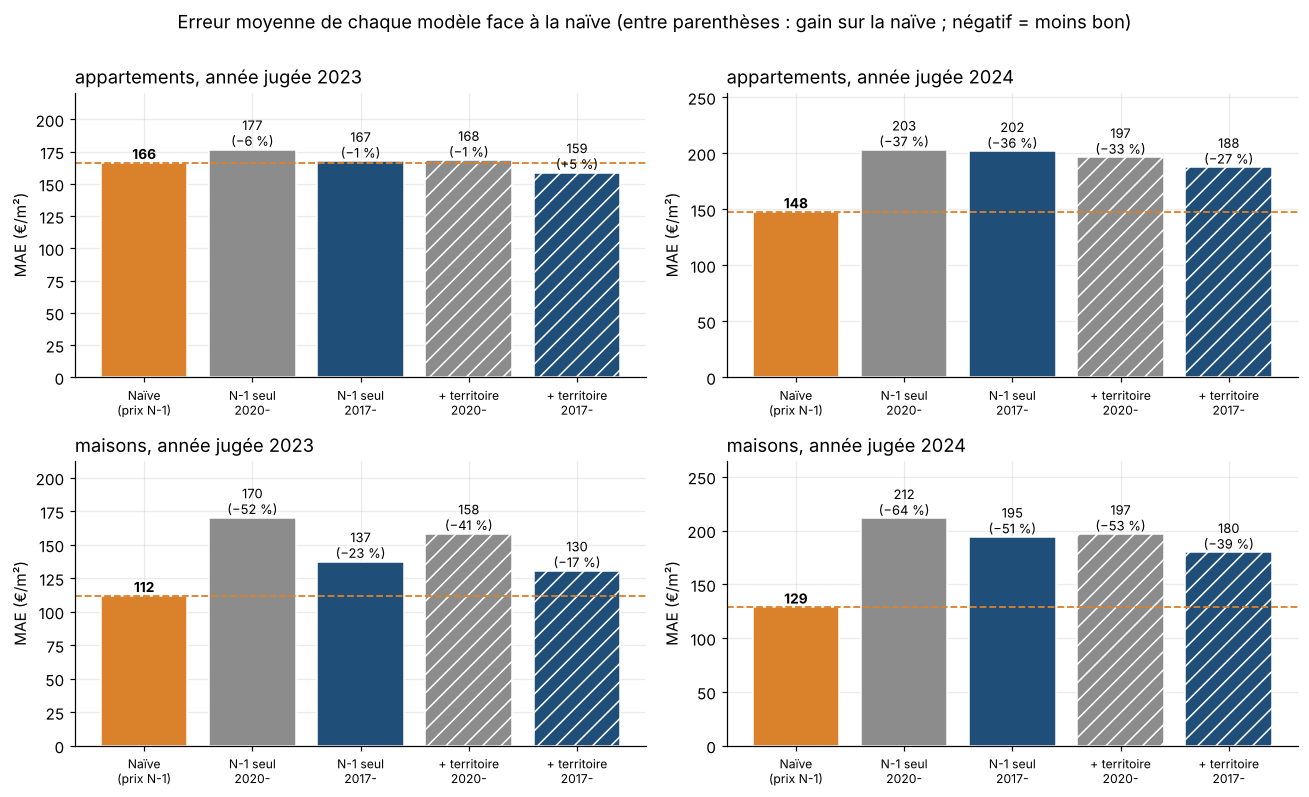

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
for i, tb in enumerate(TYPES):
    for j, a in enumerate(ANNEES):
        ax = axes[i, j]
        d = mesures[(mesures["type de bien"] == tb) & (mesures["année jugée"] == a)].set_index(["modèle", "début"])
        naive = d["MAE naïve"].iloc[0]
        vals = [naive] + [d.loc[s, "MAE"] for s in SCEN]
        x = np.arange(5)
        ax.bar(x, vals, color=[ORANGE] + COL4, hatch=[""] + HAT4, edgecolor="white")
        ax.text(0, naive + 3, f"{naive:.0f}", ha="center", fontsize=9, fontweight="bold")
        for xi, v in zip(x[1:], vals[1:]):
            ax.text(xi, v + 3, f"{v:.0f}\n({(1 - v / naive) * 100:+.0f} %)".replace("-", "−"), ha="center", fontsize=8.5)
        ax.axhline(naive, color=ORANGE, lw=1.2, ls="--")
        ax.set_xticks(x)
        ax.set_xticklabels(["Naïve\n(prix N-1)"] + LAB4, fontsize=8)
        ax.set_title(f"{tb}s, année jugée {a}", loc="left")
        ax.set_ylabel("MAE (€/m²)")
        ax.set_ylim(0, max(vals) * 1.25)
fig.suptitle("Erreur moyenne de chaque modèle face à la naïve (entre parenthèses : gain sur la naïve ; négatif = moins bon)", y=1.0)
fig.tight_layout()
plt.show()

In [7]:
gains = principal.pivot_table(index=["type de bien", "année jugée", "modèle"], columns="début", values="MAE")
n_baisse = int((gains[2017] < gains[2020]).sum())
positifs = principal[principal["gain sur la naïve (%)"] > 0]
txt_pos = "; ".join(f"{r['modèle']} {r['début']}- sur les {r['type de bien']}s {r['année jugée']} ({fr(r['gain sur la naïve (%)'], signe=True)} %)" for _, r in positifs.iterrows()) or "aucun"
n2024 = int((principal[principal["année jugée"] == 2024]["gain sur la naïve (%)"] < 0).sum())
lecture(f"La MAE baisse avec la période longue dans {n_baisse} cas sur {len(gains)} (type de bien × année jugée × modèle). Résultats au-dessus de la naïve : {txt_pos}. "
        f"En 2024, {n2024} scénarios sur {int((principal['année jugée'] == 2024).sum())} sont moins bons que la naïve. "
        f"Les biais des modèles sont tous positifs (ils surestiment), y compris en 2023 où la naïve sous-estime "
        f"({fr(principal[(principal['année jugée'] == 2023) & (principal['type de bien'] == 'appartement')]['biais naïve'].iloc[0], 0, True)} €/m² pour les appartements, "
        f"{fr(principal[(principal['année jugée'] == 2023) & (principal['type de bien'] == 'maison')]['biais naïve'].iloc[0], 0, True)} pour les maisons).")

**Lecture.** La MAE baisse avec la période longue dans 8 cas sur 8 (type de bien × année jugée × modèle). Résultats au-dessus de la naïve : prix N-1 + territoire 2017- sur les appartements 2023 (+4,6 %). En 2024, 8 scénarios sur 8 sont moins bons que la naïve. Les biais des modèles sont tous positifs (ils surestiment), y compris en 2023 où la naïve sous-estime (−65 €/m² pour les appartements, −30 pour les maisons).

### 4.2 Question de H4 : ce que la période longue change dans la prévision

Le premier graphique compare, pour chaque année jugée, l'évolution annuelle médiane du prix **réelle** à celle que prévoit chaque modèle (la naïve prévoit 0 % par construction). Le second tableau teste la différence d'erreur entre 2017- et 2020-, à modèle égal.

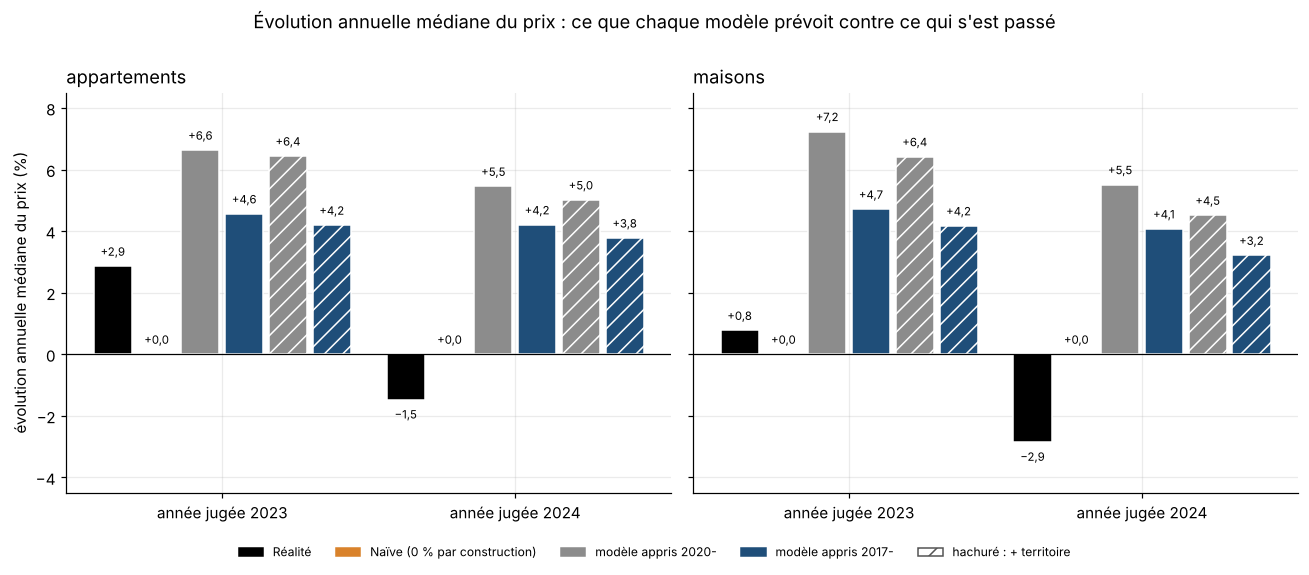

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
etiq = ["Réalité", "Naïve", "N-1 seul\n2020-", "N-1 seul\n2017-", "+ territoire\n2020-", "+ territoire\n2017-"]
couls = ["black", ORANGE, GRIS, BLEU, GRIS, BLEU]
evol_med = {}
for ax, tb in zip(axes, TYPES):
    largeur = 0.13
    for k, a in enumerate(ANNEES):
        e = sel(a, tb)
        reel = evol_reel(e).median()
        vals = [reel, 0.0] + [evol(previsions[(m, d_, a)], e).median() for (m, d_) in SCEN]
        evol_med[(tb, a)] = vals
        for q, (v, c_) in enumerate(zip(vals, couls)):
            xpos = k + (q - 2.5) * largeur * 1.15
            ax.bar(xpos, v, width=largeur, color=c_, hatch="//" if q in (4, 5) else "", edgecolor="white")
            ax.text(xpos, v + (0.25 if v >= 0 else -0.25), fr(v, 1, True), ha="center", va="bottom" if v >= 0 else "top", fontsize=7.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"année jugée {a}" for a in ANNEES])
    ax.set_title(f"{tb}s", loc="left")
    ax.set_ylim(-4.5, 8.5)
axes[0].set_ylabel("évolution annuelle médiane du prix (%)")
fig.legend(handles=[Patch(color="black", label="Réalité"), Patch(color=ORANGE, label="Naïve (0 % par construction)"),
                    Patch(color=GRIS, label="modèle appris 2020-"), Patch(color=BLEU, label="modèle appris 2017-"),
                    Patch(facecolor="white", edgecolor="#555", hatch="//", label="hachuré : + territoire")],
           frameon=False, fontsize=8, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Évolution annuelle médiane du prix : ce que chaque modèle prévoit contre ce qui s'est passé", y=1.0)
fig.tight_layout()
plt.show()

In [9]:
def bootstrap_bv(ecart, bv, n=commun.N_TIRAGES, graine=commun.GRAINE):
    """Écart moyen et IC 95 % par bootstrap des bassins de vie (même méthode que commun.tester)."""
    rng = np.random.default_rng(graine)
    par = ecart.groupby(bv.to_numpy()).agg(["sum", "count"])
    s, k = par["sum"].to_numpy(), par["count"].to_numpy()
    tirages = rng.integers(0, len(par), size=(n, len(par)))
    moy = s[tirages].sum(axis=1) / k[tirages].sum(axis=1)
    return ecart.mean(), *np.percentile(moy, [2.5, 97.5])


lignes = []
for modele in MODELES:
    for annee in ANNEES:
        for tb in TYPES:
            e = sel(annee, tb)
            ecart = (previsions[(modele, 2017, annee)].loc[e.index] - e[CIBLE]).abs() \
                  - (previsions[(modele, 2020, annee)].loc[e.index] - e[CIBLE]).abs()
            m, bas, haut = bootstrap_bv(ecart, e["BV2022"])
            lignes.append({"type de bien": tb, "année jugée": annee, "modèle": modele,
                           "2017- moins 2020- (€/m²)": m, "IC bas": bas, "IC haut": haut,
                           "verdict": "période longue meilleure" if haut < 0 else ("période longue moins bonne" if bas > 0 else "non net")})
ecarts_periode = pd.DataFrame(lignes).sort_values(["type de bien", "année jugée", "modèle"]).reset_index(drop=True)
ecarts_periode.round(1)

,type de bien,année jugée,modèle,2017- moins 2020- (€/m²),IC bas,IC haut,verdict
0,appartement,2023,prix N-1 + territoire,-9.5,-16.5,0.6,non net
1,appartement,2023,prix N-1 seul,-9.2,-17.3,3.5,non net
2,appartement,2024,prix N-1 + territoire,-8.8,-20.8,10.1,non net
3,appartement,2024,prix N-1 seul,-1.4,-12.6,16.9,non net
4,maison,2023,prix N-1 + territoire,-27.7,-29.7,-25.5,période longue meilleure
5,maison,2023,prix N-1 seul,-32.7,-34.9,-30.6,période longue meilleure
6,maison,2024,prix N-1 + territoire,-17.0,-18.7,-15.0,période longue meilleure
7,maison,2024,prix N-1 seul,-17.2,-18.2,-16.1,période longue meilleure


In [10]:
e24 = {tb: evol_med[(tb, 2024)] for tb in TYPES}
nets = ecarts_periode["verdict"].eq("période longue meilleure")
nm = int(nets[ecarts_periode["type de bien"] == "maison"].sum())
na = int(nets[ecarts_periode["type de bien"] == "appartement"].sum())
em = ecarts_periode[ecarts_periode["type de bien"] == "maison"]["2017- moins 2020- (€/m²)"]
ea = ecarts_periode[ecarts_periode["type de bien"] == "appartement"]["2017- moins 2020- (€/m²)"]
lecture(f"En 2024, le prix médian a évolué de {fr(e24['appartement'][0], 1, True)} % (appartements) et {fr(e24['maison'][0], 1, True)} % (maisons). "
        f"Le modèle complet appris sur 2020- prévoit {fr(e24['appartement'][4], 1, True)} % et {fr(e24['maison'][4], 1, True)} % ; appris sur 2017-, "
        f"{fr(e24['appartement'][5], 1, True)} % et {fr(e24['maison'][5], 1, True)} % : la période longue rapproche la prévision de la réalité sans l'atteindre. "
        f"Le test apparié confirme l'effet pour les maisons ({nm} cas sur 4 nets, gain de {fr(-em.max(), 0)} à {fr(-em.min(), 0)} €/m²) ; "
        f"pour les appartements, les écarts vont dans le même sens ({fr(ea.min(), 0, True)} à {fr(ea.max(), 0, True)} €/m²) mais {4 - na} intervalles de confiance sur 4 contiennent 0. "
        "Les appartements ont moins de territoires (environ 700 bassins de vie contre 1 600 pour les maisons) : les intervalles sont plus larges et l'on ne peut pas conclure pour eux.")

**Lecture.** En 2024, le prix médian a évolué de −1,5 % (appartements) et −2,9 % (maisons). Le modèle complet appris sur 2020- prévoit +5,0 % et +4,5 % ; appris sur 2017-, +3,8 % et +3,2 % : la période longue rapproche la prévision de la réalité sans l'atteindre. Le test apparié confirme l'effet pour les maisons (4 cas sur 4 nets, gain de 17 à 33 €/m²) ; pour les appartements, les écarts vont dans le même sens (−10 à −1 €/m²) mais 4 intervalles de confiance sur 4 contiennent 0. Les appartements ont moins de territoires (environ 700 bassins de vie contre 1 600 pour les maisons) : les intervalles sont plus larges et l'on ne peut pas conclure pour eux.

### 4.3 Règle de décision : chaque modèle contre la naïve

Part des sous-bassins où le modèle fait mieux que la naïve (50 % = égalité), puis le verdict du test (écart de MAE avec la naïve, intervalle de confiance à 95 % par bootstrap sur les bassins de vie, test de Wilcoxon apparié).

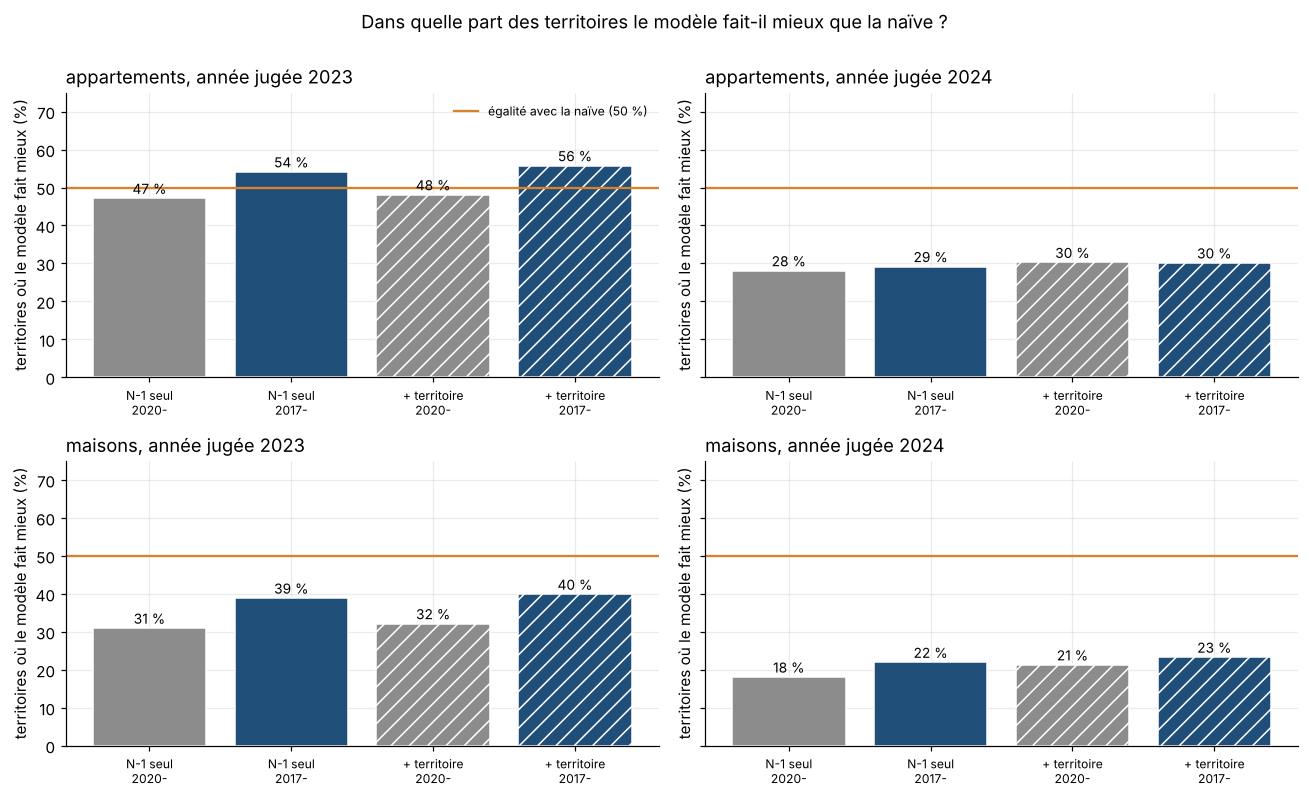

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), sharey=True)
part_gagnante = {}
for i, tb in enumerate(TYPES):
    for j, a in enumerate(ANNEES):
        ax = axes[i, j]
        e = sel(a, tb)
        err_n = (e["prix_n1"] - e[CIBLE]).abs()
        part = [((previsions[(m, d_, a)].loc[e.index] - e[CIBLE]).abs() < err_n).mean() * 100 for (m, d_) in SCEN]
        part_gagnante[(tb, a)] = part
        x = np.arange(4)
        ax.bar(x, part, color=COL4, hatch=HAT4, edgecolor="white")
        for xi, v in zip(x, part):
            ax.text(xi, v + 1.2, f"{v:.0f} %", ha="center", fontsize=9)
        ax.axhline(50, color=ORANGE, lw=1.5, label="égalité avec la naïve (50 %)")
        ax.set_xticks(x)
        ax.set_xticklabels(LAB4, fontsize=8)
        ax.set_ylim(0, 75)
        ax.set_title(f"{tb}s, année jugée {a}", loc="left")
        ax.set_ylabel("territoires où le modèle fait mieux (%)")
        if i == 0 and j == 0:
            ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Dans quelle part des territoires le modèle fait-il mieux que la naïve ?", y=1.0)
fig.tight_layout()
plt.show()

In [12]:
t = pd.DataFrame(tests)
t[["modèle", "début"]] = t["modèle"].str.extract(r"^(.*) \| (\d{4})-$")
t["début"] = t["début"].astype(int)
t["verdict"] = np.where(t["IC 95 % haut (€/m²)"] < 0, "le modèle bat la naïve",
                        np.where(t["IC 95 % bas (€/m²)"] > 0, "la naïve est meilleure", "non net"))
verdicts = t[["type de bien", "année jugée", "modèle", "début", "écart de MAE avec la naïve (€/m²)", "IC 95 % bas (€/m²)",
              "IC 95 % haut (€/m²)", "p-value Wilcoxon", "rang-bisériale", "verdict"]].sort_values(
    ["type de bien", "année jugée", "modèle", "début"], ascending=[True, True, True, False]).round(2).reset_index(drop=True)
verdicts

,type de bien,année jugée,modèle,début,écart de MAE avec la naïve (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale,verdict
0,appartement,2023,prix N-1 + territoire,2020,1.88,-9.51,12.94,0.34,0.04,non net
1,appartement,2023,prix N-1 + territoire,2017,-7.64,-20.24,6.25,0.04,-0.08,non net
2,appartement,2023,prix N-1 seul,2020,10.30,-3.69,25.72,0.03,0.08,non net
3,appartement,2023,prix N-1 seul,2017,1.15,-17.97,25.75,0.34,-0.04,non net
4,appartement,2024,prix N-1 + territoire,2020,48.66,29.47,63.26,0.00,0.46,la naïve est meilleure
5,appartement,2024,prix N-1 + territoire,2017,39.82,32.29,46.77,0.00,0.46,la naïve est meilleure
6,appartement,2024,prix N-1 seul,2020,55.30,46.55,63.12,0.00,0.55,la naïve est meilleure
7,appartement,2024,prix N-1 seul,2017,53.95,39.34,70.22,0.00,0.53,la naïve est meilleure
8,maison,2023,prix N-1 + territoire,2020,46.33,39.55,52.73,0.00,0.42,la naïve est meilleure
9,maison,2023,prix N-1 + territoire,2017,18.68,13.17,23.59,0.00,0.26,la naïve est meilleure


In [13]:
n_bat = int((t["verdict"] == "le modèle bat la naïve").sum())
n_naive = int((t["verdict"] == "la naïve est meilleure").sum())
n_nn = int((t["verdict"] == "non net").sum())
p24 = np.array([part_gagnante[(tb, 2024)] for tb in TYPES])
p23a, p23m = np.array(part_gagnante[("appartement", 2023)]), np.array(part_gagnante[("maison", 2023)])
lecture(f"Règle de décision (1.5) : un modèle doit avoir un intervalle de confiance entièrement sous 0. Sur {len(t)} scénarios, {n_bat} le satisfont, "
        f"{n_naive} sont nettement moins bons que la naïve et {n_nn} ne sont pas tranchés. "
        f"En 2024, le modèle ne fait mieux que la naïve que dans {fr(p24.min(), 0)} % à {fr(p24.max(), 0)} % des territoires ; "
        f"en 2023, les appartements sont proches de l'égalité ({fr(p23a.min(), 0)} % à {fr(p23a.max(), 0)} %) et les maisons restent sous 50 % ({fr(p23m.min(), 0)} % à {fr(p23m.max(), 0)} %). "
        "La période longue ajoute quelques points de victoire partout et rapproche de la naïve sans la dépasser.")

**Lecture.** Règle de décision (1.5) : un modèle doit avoir un intervalle de confiance entièrement sous 0. Sur 16 scénarios, 0 le satisfont, 12 sont nettement moins bons que la naïve et 4 ne sont pas tranchés. En 2024, le modèle ne fait mieux que la naïve que dans 18 % à 30 % des territoires ; en 2023, les appartements sont proches de l'égalité (47 % à 56 %) et les maisons restent sous 50 % (31 % à 40 %). La période longue ajoute quelques points de victoire partout et rapproche de la naïve sans la dépasser.

### 4.4 Décomposition de l'erreur : part commune et part propre

Même diagnostic qu'au niveau 1 (T1). La **part commune** est l'erreur moyenne signée de tous les territoires (le biais) ; la **part propre** est ce qui reste quand on la retire. Le graphique empile la MAE sans part commune (bleu) et ce que la part commune ajoute (orange). La ligne pleine est la MAE de la naïve ; la ligne pointillée, la MAE de la naïve sans sa part commune. Retirer la part commune est un outil de diagnostic, pas un modèle : il utilise l'erreur réelle de l'année jugée.

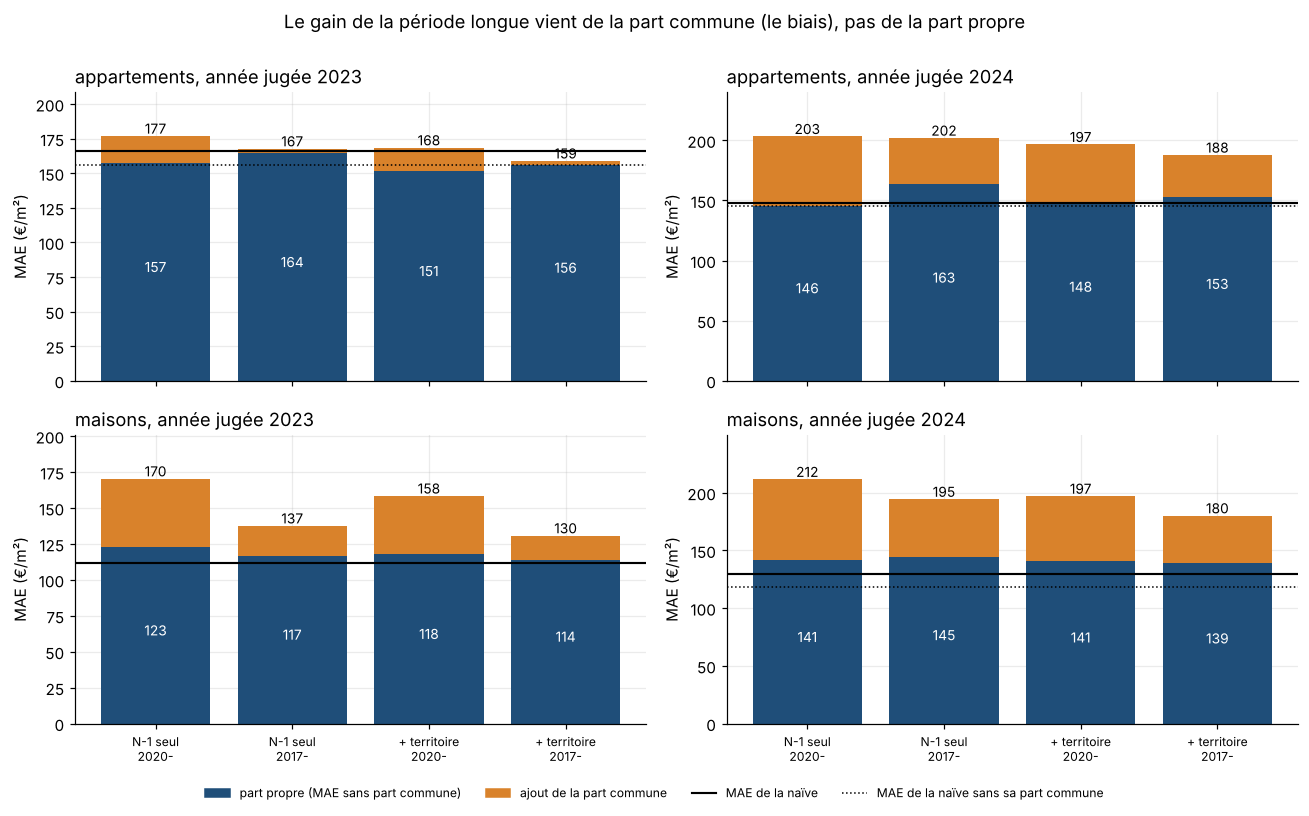

,type de bien,année jugée,modèle,début,biais,MAE,MAE sans part commune,part commune (€/m²),MAE naïve,MAE naïve sans part commune
0,appartement,2023,prix N-1 + territoire,2020,86.8,168.2,151.3,16.9,166.3,156.2
1,appartement,2023,prix N-1 + territoire,2017,40.7,158.7,156.2,2.5,166.3,156.2
2,appartement,2023,prix N-1 seul,2020,90.3,176.6,157.2,19.4,166.3,156.2
3,appartement,2023,prix N-1 seul,2017,58.2,167.5,164.4,3.1,166.3,156.2
4,appartement,2024,prix N-1 + territoire,2020,149.5,196.7,148.0,48.6,148.0,145.1
5,appartement,2024,prix N-1 + territoire,2017,136.0,187.8,152.8,35.0,148.0,145.1
6,appartement,2024,prix N-1 seul,2020,161.7,203.3,145.6,57.7,148.0,145.1
7,appartement,2024,prix N-1 seul,2017,154.4,202.0,163.3,38.6,148.0,145.1
8,maison,2023,prix N-1 + territoire,2020,119.8,158.0,117.7,40.3,111.7,111.6
9,maison,2023,prix N-1 + territoire,2017,72.1,130.4,113.9,16.5,111.7,111.6


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
ordre = [("prix N-1 seul", 2020), ("prix N-1 seul", 2017), ("prix N-1 + territoire", 2020), ("prix N-1 + territoire", 2017)]
for i, tb in enumerate(TYPES):
    for j, annee in enumerate(ANNEES):
        ax = axes[i, j]
        d = mesures[(mesures["type de bien"] == tb) & (mesures["année jugée"] == annee)].set_index(["modèle", "début"])
        propre = [d.loc[o, "MAE sans part commune"] for o in ordre]
        total = [d.loc[o, "MAE"] for o in ordre]
        x = np.arange(4)
        ax.bar(x, propre, color=BLEU)
        ax.bar(x, np.array(total) - np.array(propre), bottom=propre, color=ORANGE)
        for xi, p_, t_ in zip(x, propre, total):
            ax.text(xi, p_ / 2, f"{p_:.0f}", ha="center", color="white", fontsize=9)
            ax.text(xi, t_ + 2, f"{t_:.0f}", ha="center", fontsize=9)
        ax.axhline(d["MAE naïve"].iloc[0], color="black", lw=1.4)
        ax.axhline(d["MAE naïve sans part commune"].iloc[0], color="black", lw=1, ls=":")
        ax.set_xticks(x)
        ax.set_xticklabels(LAB4, fontsize=8)
        ax.set_title(f"{tb}s, année jugée {annee}", loc="left")
        ax.set_ylabel("MAE (€/m²)")
        ax.set_ylim(0, max(total) * 1.18)
fig.legend(handles=[Patch(color=BLEU, label="part propre (MAE sans part commune)"), Patch(color=ORANGE, label="ajout de la part commune"),
                    Line2D([], [], color="black", lw=1.4, label="MAE de la naïve"),
                    Line2D([], [], color="black", lw=1, ls=":", label="MAE de la naïve sans sa part commune")],
           frameon=False, fontsize=8, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Le gain de la période longue vient de la part commune (le biais), pas de la part propre", y=1.0)
fig.tight_layout()
plt.show()
decomp = mesures[mesures["début"].isin([2017, 2020])].assign(
    **{"part commune (€/m²)": lambda x: x["MAE"] - x["MAE sans part commune"]}).sort_values(
    ["type de bien", "année jugée", "modèle", "début"], ascending=[True, True, True, False])
decomp[["type de bien", "année jugée", "modèle", "début", "biais", "MAE", "MAE sans part commune", "part commune (€/m²)", "MAE naïve", "MAE naïve sans part commune"]].round(1).reset_index(drop=True)

In [15]:
dp = decomp.pivot_table(index=["type de bien", "année jugée", "modèle"], columns="début", values=["MAE sans part commune", "part commune (€/m²)"])
d_propre = dp["MAE sans part commune"][2017] - dp["MAE sans part commune"][2020]
d_commune = dp["part commune (€/m²)"][2017] - dp["part commune (€/m²)"][2020]
cplt = (slice(None), slice(None), "prix N-1 + territoire")
x24 = decomp[(decomp["type de bien"] == "appartement") & (decomp["année jugée"] == 2024) & (decomp["modèle"] == "prix N-1 + territoire")].set_index("début")
lecture(f"Pour le modèle complet, la part propre varie peu avec la période longue ({fr(d_propre.loc[cplt].min(), 0, True)} à {fr(d_propre.loc[cplt].max(), 0, True)} €/m² selon les cas) "
        f"alors que la part commune baisse de {fr(-d_commune.loc[cplt].max(), 0)} à {fr(-d_commune.loc[cplt].min(), 0)} €/m². "
        f"Pour le modèle complet 2020- en 2024, la part propre des appartements ({fr(x24.loc[2020, 'MAE sans part commune'], 0)} €/m²) est égale à la MAE de la naïve "
        f"({fr(x24.loc[2020, 'MAE naïve'], 0)}) : c'est le constat du diagnostic T1 du niveau 1 ; avec la période longue elle monte à {fr(x24.loc[2017, 'MAE sans part commune'], 0)}. "
        f"Cas extrême : « prix N-1 seul » sur les appartements 2024, où la part commune baisse de {fr(-d_commune.loc[('appartement', 2024, 'prix N-1 seul')], 0)} €/m² mais où la part propre augmente de "
        f"{fr(d_propre.loc[('appartement', 2024, 'prix N-1 seul')], 0)} : la MAE ne gagne presque rien. La période longue corrige le « quand » en partie, pas le « où ».")

**Lecture.** Pour le modèle complet, la part propre varie peu avec la période longue (−4 à +5 €/m² selon les cas) alors que la part commune baisse de 14 à 24 €/m². Pour le modèle complet 2020- en 2024, la part propre des appartements (148 €/m²) est égale à la MAE de la naïve (148) : c'est le constat du diagnostic T1 du niveau 1 ; avec la période longue elle monte à 153. Cas extrême : « prix N-1 seul » sur les appartements 2024, où la part commune baisse de 19 €/m² mais où la part propre augmente de 18 : la MAE ne gagne presque rien. La période longue corrige le « quand » en partie, pas le « où ».

### 4.5 D'où vient l'erreur de prévision d'évolution : biais, dispersion ou classement

Sur l'évolution annuelle (en points de %), l'erreur quadratique se décompose exactement en trois parts : le **biais** (décalage moyen), l'**écart de dispersion** entre évolution prévue et réelle, et le **mauvais classement** des territoires (corrélation imparfaite). Pour la naïve, qui prévoit 0 % partout, tout le reste de l'erreur est de la « dispersion » : elle ne prévoit aucune différence entre territoires.

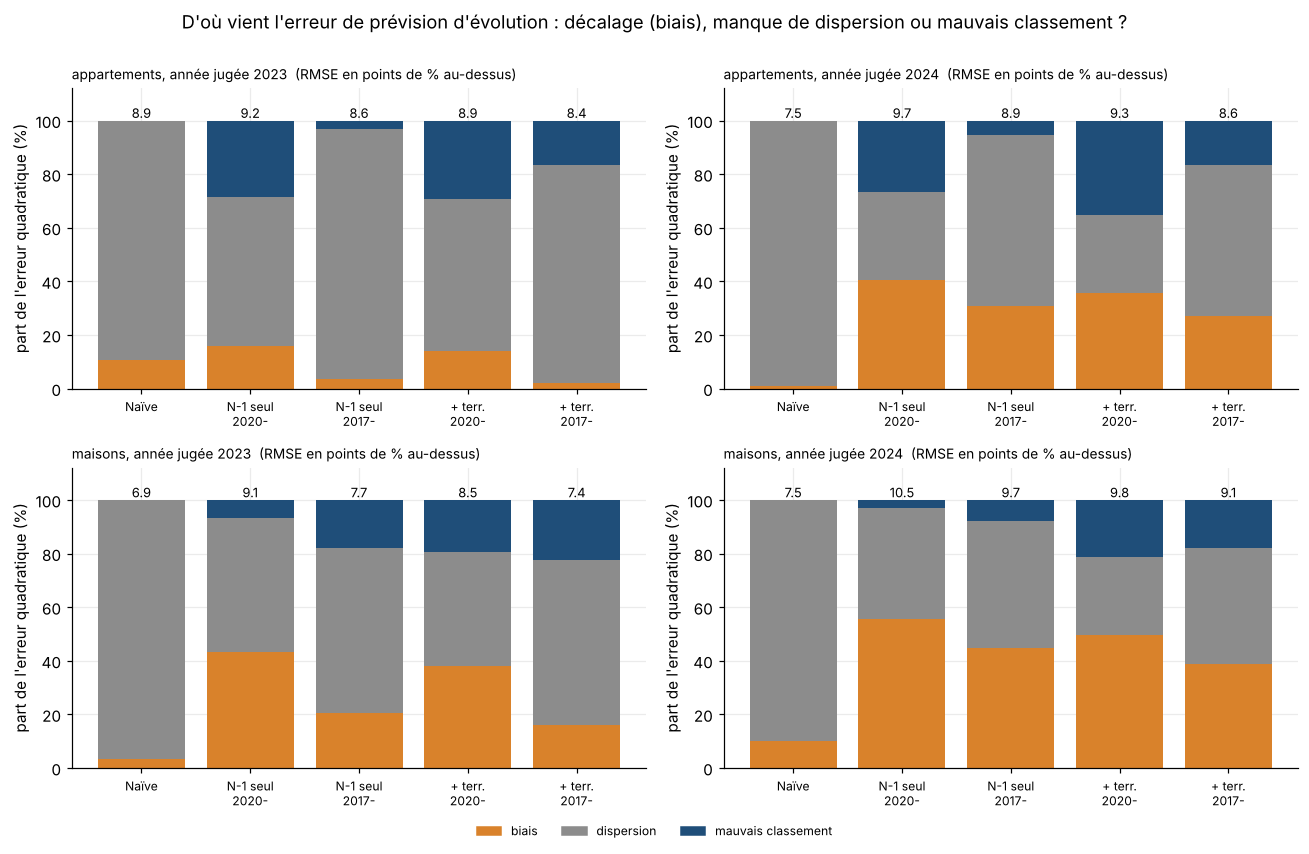

,type de bien,année jugée,scénario,RMSE (points de %),biais (%),dispersion (%),mauvais classement (%)
0,appartement,2023,Naïve,8.9,10.7,89.3,0.0
1,appartement,2023,N-1 seul 2020-,9.2,16.0,55.6,28.4
2,appartement,2023,N-1 seul 2017-,8.6,3.6,93.1,3.3
3,appartement,2023,+ terr. 2020-,8.9,13.9,57.0,29.2
4,appartement,2023,+ terr. 2017-,8.4,2.0,81.6,16.4
5,appartement,2024,Naïve,7.5,1.0,99.0,0.0
6,appartement,2024,N-1 seul 2020-,9.7,40.6,32.8,26.6
7,appartement,2024,N-1 seul 2017-,8.9,30.7,63.9,5.5
8,appartement,2024,+ terr. 2020-,9.3,35.7,28.9,35.3
9,appartement,2024,+ terr. 2017-,8.6,27.0,56.5,16.6


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
tab2 = []
for i, tb in enumerate(TYPES):
    for j, a in enumerate(ANNEES):
        ax = axes[i, j]
        e = sel(a, tb)
        reel = evol_reel(e)
        preds = [pd.Series(0.0, index=e.index)] + [evol(previsions[(m, d_, a)], e) for (m, d_) in SCEN]
        comp = []
        for nom, p in zip(LAB5, preds):
            err = p - reel
            biais2 = err.mean() ** 2
            sp, sr = p.std(ddof=0), reel.std(ddof=0)
            rho_ = np.corrcoef(p, reel)[0, 1] if sp > 0 else 0.0
            disp = (sp - sr) ** 2
            corr = 2 * sp * sr * (1 - rho_)
            mse = biais2 + disp + corr
            assert abs(mse - (err ** 2).mean()) < 1e-6        # la décomposition est exacte
            comp.append((biais2 / mse * 100, disp / mse * 100, corr / mse * 100, np.sqrt(mse)))
            tab2.append({"type de bien": tb, "année jugée": a, "scénario": nom.replace("\n", " "), "RMSE (points de %)": np.sqrt(mse),
                         "biais (%)": biais2 / mse * 100, "dispersion (%)": disp / mse * 100, "mauvais classement (%)": corr / mse * 100})
        x = np.arange(5)
        bot = np.zeros(5)
        for k, (nom, c_) in enumerate([("biais", ORANGE), ("dispersion", GRIS), ("mauvais classement", BLEU)]):
            v = np.array([c[k] for c in comp])
            ax.bar(x, v, bottom=bot, color=c_)
            bot += v
        for xi, c in zip(x, comp):
            ax.text(xi, 101, f"{c[3]:.1f}", ha="center", fontsize=8.5)
        ax.set_xticks(x)
        ax.set_xticklabels(LAB5, fontsize=8)
        ax.set_ylim(0, 112)
        ax.set_ylabel("part de l'erreur quadratique (%)")
        ax.set_title(f"{tb}s, année jugée {a}  (RMSE en points de % au-dessus)", loc="left", fontsize=9)
fig.legend(handles=[Patch(color=ORANGE, label="biais"), Patch(color=GRIS, label="dispersion"), Patch(color=BLEU, label="mauvais classement")],
           frameon=False, fontsize=8, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("D'où vient l'erreur de prévision d'évolution : décalage (biais), manque de dispersion ou mauvais classement ?", y=1.0)
fig.tight_layout()
plt.show()
tab2 = pd.DataFrame(tab2)
tab2.round(1)

In [17]:
d24 = tab2[tab2["année jugée"] == 2024]
naive24 = d24[d24["scénario"] == "Naïve"].set_index("type de bien")["RMSE (points de %)"]
mod24 = d24[d24["scénario"] != "Naïve"]
lecture(f"En 2024, la naïve a la plus petite erreur d'évolution ({fr(naive24['appartement'])} points de % pour les appartements, {fr(naive24['maison'])} pour les maisons), "
        f"contre {fr(mod24['RMSE (points de %)'].min())} à {fr(mod24['RMSE (points de %)'].max())} pour les modèles. "
        f"Le biais pèse de {fr(mod24['biais (%)'].min(), 0)} % à {fr(mod24['biais (%)'].max(), 0)} % de l'erreur quadratique des modèles en 2024 (au plus {fr(d24[d24['scénario'] == 'Naïve']['biais (%)'].max(), 0)} % pour la naïve). "
        "Les modèles réduisent la part « dispersion » en prévoyant des différences entre territoires, mais ils les prévoient mal (part « mauvais classement ») et ajoutent du biais : "
        "la période longue réduit le biais, et c'est elle qui rapproche les modèles de la naïve.")

**Lecture.** En 2024, la naïve a la plus petite erreur d'évolution (7,5 points de % pour les appartements, 7,5 pour les maisons), contre 8,6 à 10,5 pour les modèles. Le biais pèse de 27 % à 56 % de l'erreur quadratique des modèles en 2024 (au plus 10 % pour la naïve). Les modèles réduisent la part « dispersion » en prévoyant des différences entre territoires, mais ils les prévoient mal (part « mauvais classement ») et ajoutent du biais : la période longue réduit le biais, et c'est elle qui rapproche les modèles de la naïve.

### 4.6 Sensibilité : combien d'années d'apprentissage faut-il ?

Même protocole, en faisant varier la première année d'apprentissage de 2017 à 2021. Cela montre si le gain vient d'une phase précise du marché ou s'il augmente avec la longueur de la période. Pour la fenêtre 2023, un début en 2021 laisse deux années d'apprentissage (un seul pli de réglage).

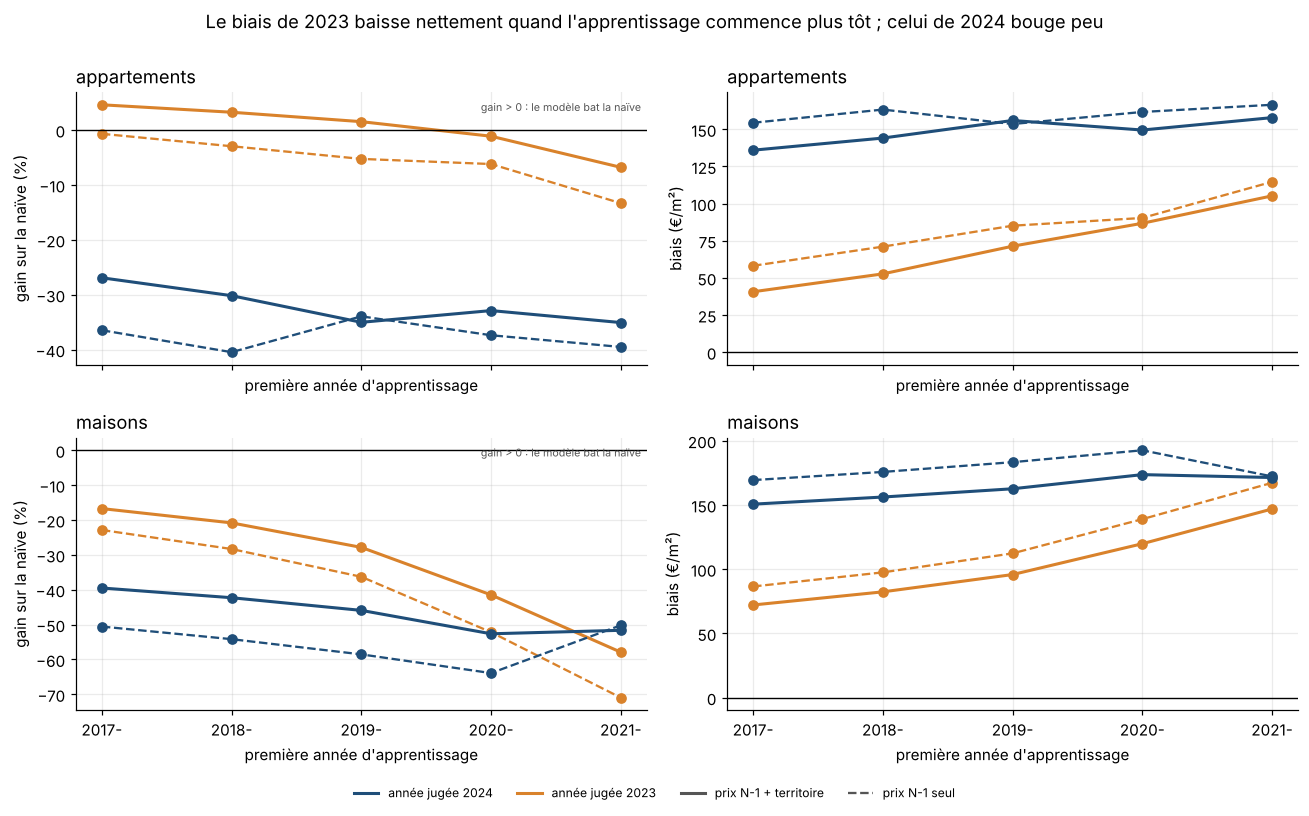

début                                            2017   2018   2019   2020  \
type de bien année jugée modèle                                              
appartement  2023        prix N-1 + territoire   41.0   53.0   71.0   87.0   
                         prix N-1 seul           58.0   71.0   85.0   90.0   
             2024        prix N-1 + territoire  136.0  144.0  156.0  150.0   
                         prix N-1 seul          154.0  163.0  154.0  162.0   
maison       2023        prix N-1 + territoire   72.0   82.0   96.0  120.0   
                         prix N-1 seul           87.0   98.0  112.0  139.0   
             2024        prix N-1 + territoire  151.0  156.0  163.0  174.0   
                         prix N-1 seul          169.0  176.0  183.0  193.0   

début                                            2021  
type de bien année jugée modèle                        
appartement  2023        prix N-1 + territoire  105.0  
                         prix N-1 seul          115.0  
             2024        prix N-1 + territoire  158.0  
                         prix N-1 seul          167.0  
maison       2023        prix N-1 + territoire  147.0  
                         prix N-1 seul          167.0  
             2024        prix N-1 + territoire  171.0  
                         prix N-1 seul          172.0

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for i, tb in enumerate(TYPES):
    for k, (col, titre) in enumerate([("gain sur la naïve (%)", "gain sur la naïve (%)"), ("biais", "biais (€/m²)")]):
        ax = axes[i, k]
        for annee, couleur in zip(ANNEES, [ORANGE, BLEU]):
            for modele, style in zip(MODELES, ["--", "-"]):
                d = mesures[(mesures["type de bien"] == tb) & (mesures["année jugée"] == annee) & (mesures["modèle"] == modele)].sort_values("début")
                ax.plot(d["début"], d[col], style, color=couleur, marker="o", lw=2 if style == "-" else 1.5)
        ax.axhline(0, color="black", lw=0.9)
        ax.set_xticks(DEBUTS)
        ax.set_xticklabels([f"{x}-" for x in DEBUTS])
        ax.set_title(f"{tb}s", loc="left")
        ax.set_ylabel(titre)
        ax.set_xlabel("première année d'apprentissage")
        if k == 0:
            ax.annotate("gain > 0 : le modèle bat la naïve", xy=(0.99, 0.97), xycoords="axes fraction", ha="right", va="top", fontsize=7, color="#555")
fig.legend(handles=[Line2D([], [], color=BLEU, lw=2, label="année jugée 2024"),
                    Line2D([], [], color=ORANGE, lw=2, label="année jugée 2023"),
                    Line2D([], [], color="#555", lw=2, ls="-", label="prix N-1 + territoire"),
                    Line2D([], [], color="#555", lw=1.5, ls="--", label="prix N-1 seul")],
           frameon=False, fontsize=8, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Le biais de 2023 baisse nettement quand l'apprentissage commence plus tôt ; celui de 2024 bouge peu", y=1.0)
fig.tight_layout()
plt.show()
sens = mesures.pivot_table(index=["type de bien", "année jugée", "modèle"], columns="début", values="biais")
sens.round(0)

In [19]:
c = "prix N-1 + territoire"
g23 = mesures[(mesures["année jugée"] == 2023) & (mesures["modèle"] == c) & (mesures["type de bien"] == "appartement")].set_index("début")["gain sur la naïve (%)"]
pos23 = [str(d) for d in DEBUTS if g23[d] > 0]
lecture(f"Pour 2023, chaque année ajoutée à l'apprentissage fait baisser le biais : le modèle complet passe de {fr(sens.loc[('appartement', 2023, c), 2021], 0, True)} €/m² (début 2021) à "
        f"{fr(sens.loc[('appartement', 2023, c), 2017], 0, True)} (début 2017) pour les appartements, et de {fr(sens.loc[('maison', 2023, c), 2021], 0, True)} à {fr(sens.loc[('maison', 2023, c), 2017], 0, True)} pour les maisons. "
        f"Pour 2024, le biais du modèle complet bouge peu (appartements : de {fr(sens.loc[('appartement', 2024, c)].min(), 0, True)} à {fr(sens.loc[('appartement', 2024, c)].max(), 0, True)} ; "
        f"maisons : de {fr(sens.loc[('maison', 2024, c)].min(), 0, True)} à {fr(sens.loc[('maison', 2024, c)].max(), 0, True)}). "
        f"Seul le modèle complet sur appartements 2023 passe au-dessus de la naïve, et seulement avec un début en {', '.join(p + '-' for p in pos23) or 'aucune année'} : "
        "le gain tient à la quantité de phases du marché vues, pas à une année précise.")

**Lecture.** Pour 2023, chaque année ajoutée à l'apprentissage fait baisser le biais : le modèle complet passe de +105 €/m² (début 2021) à +41 (début 2017) pour les appartements, et de +147 à +72 pour les maisons. Pour 2024, le biais du modèle complet bouge peu (appartements : de +136 à +158 ; maisons : de +151 à +174). Seul le modèle complet sur appartements 2023 passe au-dessus de la naïve, et seulement avec un début en 2017-, 2018-, 2019- : le gain tient à la quantité de phases du marché vues, pas à une année précise.

### 4.7 Le modèle sait-il classer les territoires ?

Pour chaque sous-bassin : évolution prévue (axe vertical) contre évolution réelle (axe horizontal), avec la diagonale « prévision parfaite » et la naïve à 0 %. La corrélation de rang ρ (Spearman) mesure la capacité à dire quels territoires montent plus que les autres. La naïve prévoit 0 % partout : ρ n'est pas défini pour elle. Pour « prix N-1 seul », la prévision ne dépend que du prix N-1 : ρ y mesure le seul effet de retour à la moyenne.

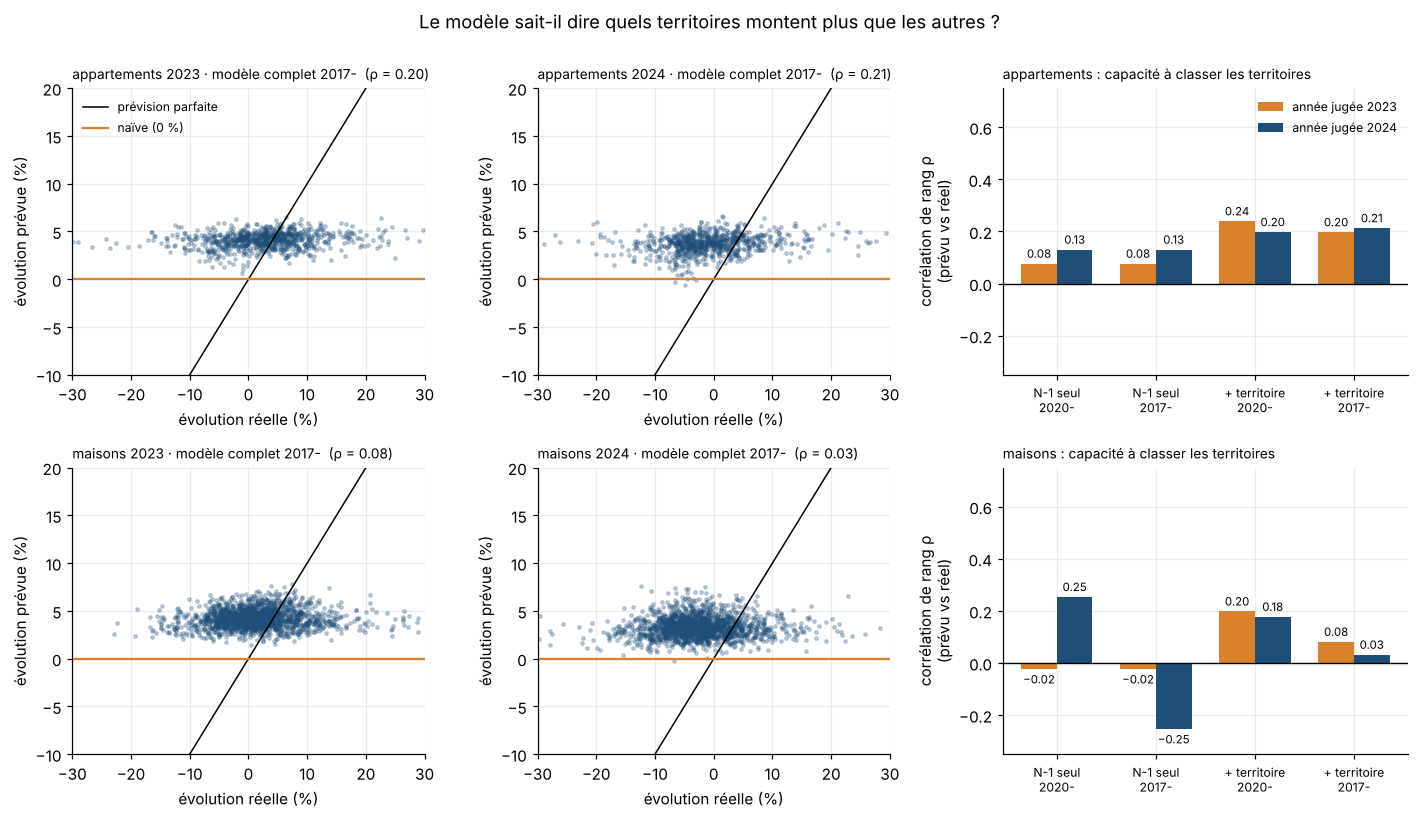

modèle                   prix N-1 + territoire       prix N-1 seul      
début                                     2017  2020          2017  2020
type de bien année jugée                                                
appartement  2023                         0.20  0.24          0.08  0.08
             2024                         0.21  0.20          0.13  0.13
maison       2023                         0.08  0.20         -0.02 -0.02
             2024                         0.03  0.18         -0.25  0.25

In [20]:
fig = plt.figure(figsize=(13, 7.4))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.15])
rho_tab = []
for i, tb in enumerate(TYPES):
    for j, a in enumerate(ANNEES):
        ax = fig.add_subplot(gs[i, j])
        e = sel(a, tb)
        reel = evol_reel(e)
        prev = evol(previsions[("prix N-1 + territoire", 2017, a)], e)
        ax.scatter(reel, prev, s=5, alpha=0.25, color=BLEU, rasterized=True)
        ax.plot((-30, 30), (-30, 30), color="black", lw=1, label="prévision parfaite")
        ax.axhline(0, color=ORANGE, lw=1.5, label="naïve (0 %)")
        ax.set_xlim(-30, 30)
        ax.set_ylim(-10, 20)
        ax.set_xlabel("évolution réelle (%)")
        ax.set_ylabel("évolution prévue (%)")
        ax.set_title(f"{tb}s {a} · modèle complet 2017-  (ρ = {spearmanr(reel, prev).statistic:.2f})", loc="left", fontsize=9)
        if i == 0 and j == 0:
            ax.legend(frameon=False, fontsize=8, loc="upper left")
    for a in ANNEES:
        e = sel(a, tb)
        reel = evol_reel(e)
        for (m, d_) in SCEN:
            rho_tab.append({"type de bien": tb, "année jugée": a, "modèle": m, "début": d_, "rho": spearmanr(reel, evol(previsions[(m, d_, a)], e)).statistic})
rho = pd.DataFrame(rho_tab)
for i, tb in enumerate(TYPES):
    ax = fig.add_subplot(gs[i, 2])
    x, larg = np.arange(4), 0.36
    for k, (a, c_) in enumerate(zip(ANNEES, [ORANGE, BLEU])):
        v = [rho[(rho["type de bien"] == tb) & (rho["année jugée"] == a) & (rho["modèle"] == m) & (rho["début"] == d_)]["rho"].iloc[0] for (m, d_) in SCEN]
        ax.bar(x + (k - 0.5) * larg, v, width=larg, color=c_, label=f"année jugée {a}")
        for xi, vi in zip(x + (k - 0.5) * larg, v):
            ax.text(xi, vi + (0.012 if vi >= 0 else -0.012), f"{vi:.2f}".replace("-", "−"), ha="center", va="bottom" if vi >= 0 else "top", fontsize=7.5)
    ax.axhline(0, color="black", lw=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(LAB4, fontsize=8)
    ax.set_ylabel("corrélation de rang ρ\n(prévu vs réel)")
    ax.set_ylim(-0.35, 0.75)
    ax.set_title(f"{tb}s : capacité à classer les territoires", loc="left", fontsize=9)
    if i == 0:
        ax.legend(frameon=False, fontsize=8)
fig.suptitle("Le modèle sait-il dire quels territoires montent plus que les autres ?", y=1.0)
fig.tight_layout()
plt.show()
rho.pivot_table(index=["type de bien", "année jugée"], columns=["modèle", "début"], values="rho").round(2)

In [21]:
cc = "prix N-1 + territoire"
rr = rho[rho["modèle"] == cc].pivot_table(index=["type de bien", "année jugée"], columns="début", values="rho")
lecture(f"Le modèle complet classe mal les territoires : ρ de {fr(rr.min().min(), 2)} à {fr(rr.max().max(), 2)} sur les huit scénarios, et les nuages sont plats : "
        f"il prévoit à peu près la même évolution partout (environ {fr(evol(previsions[(cc, 2017, 2024)], sel(2024, 'appartement')).median(), 0, True)} % en 2024), alors que la réalité va de −30 % à +30 %. "
        f"Pour les appartements, ρ vaut {fr(rr.loc[('appartement', 2024), 2020], 2)} (2020-) et {fr(rr.loc[('appartement', 2024), 2017], 2)} (2017-) en 2024. "
        f"Pour les maisons, la période longue **dégrade** le classement du modèle complet : de {fr(rr.loc[('maison', 2023), 2020], 2)} à {fr(rr.loc[('maison', 2023), 2017], 2)} en 2023, "
        f"de {fr(rr.loc[('maison', 2024), 2020], 2)} à {fr(rr.loc[('maison', 2024), 2017], 2)} en 2024. La période longue réduit donc l'erreur par le niveau (le biais), pas par une meilleure distinction entre territoires.")

**Lecture.** Le modèle complet classe mal les territoires : ρ de 0,03 à 0,24 sur les huit scénarios, et les nuages sont plats : il prévoit à peu près la même évolution partout (environ +4 % en 2024), alors que la réalité va de −30 % à +30 %. Pour les appartements, ρ vaut 0,20 (2020-) et 0,21 (2017-) en 2024. Pour les maisons, la période longue **dégrade** le classement du modèle complet : de 0,20 à 0,08 en 2023, de 0,18 à 0,03 en 2024. La période longue réduit donc l'erreur par le niveau (le biais), pas par une meilleure distinction entre territoires.

### 4.8 Le modèle gagne-t-il quand le marché monte ? (extension : années jugées 2021 et 2022)

**Hors règle de décision 1.5** : les années jugées de H4 restent 2023 et 2024. Ce graphique ajoute 2021 et 2022 (apprentissage 2017- jusqu'à l'année précédente, soit 4 et 5 années) pour lire l'effet de la phase du marché. À présenter comme un éclairage, pas comme un résultat de la règle de décision.

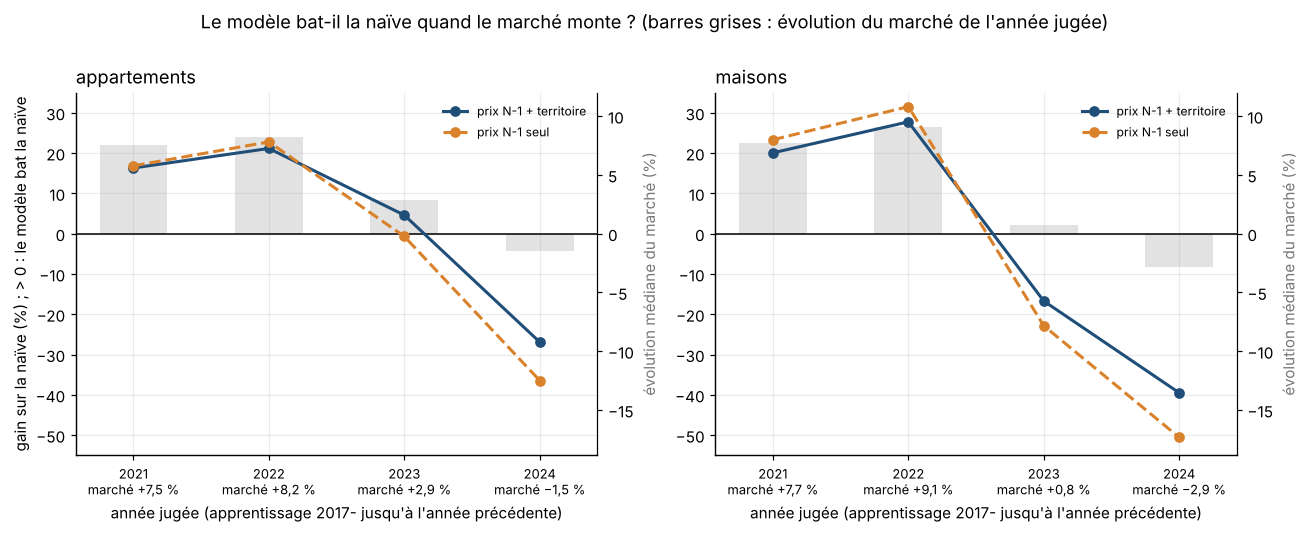

modèle                    prix N-1 + territoire  prix N-1 seul
type de bien année jugée                                      
appartement  2021                          16.3           16.8
             2022                          21.1           22.8
             2023                           4.6           -0.7
             2024                         -26.9          -36.5
maison       2021                          20.1           23.3
             2022                          27.7           31.5
             2023                         -16.7          -22.9
             2024                         -39.5          -50.6

In [22]:
F2 = fenetres(table, annees_jugees=[2021, 2022], annee_debut=2017)
lignes = []
for modele, variables in MODELES.items():
    for a, (app, ev) in F2.items():
        prev = pd.Series(np.nan, index=ev.index)
        for tb, e in app.groupby("type_bien"):
            idx = ev.index[ev.index.get_level_values("type_bien") == tb]
            prev.loc[idx] = ajuster(e, ev.loc[idx], variables)[0]
        for tb in TYPES:
            e = ev[ev.index.get_level_values("type_bien") == tb]
            mae, mn = (prev.loc[e.index] - e[CIBLE]).abs().mean(), (e["prix_n1"] - e[CIBLE]).abs().mean()
            lignes.append({"type de bien": tb, "année jugée": a, "modèle": modele, "gain sur la naïve (%)": (1 - mae / mn) * 100,
                           "marché (%)": evol_reel(e).median()})
for modele in MODELES:
    for a in ANNEES:
        for tb in TYPES:
            r = mesures[(mesures["type de bien"] == tb) & (mesures["année jugée"] == a) & (mesures["modèle"] == modele) & (mesures["début"] == 2017)].iloc[0]
            lignes.append({"type de bien": tb, "année jugée": a, "modèle": modele, "gain sur la naïve (%)": r["gain sur la naïve (%)"],
                           "marché (%)": evol_reel(sel(a, tb)).median()})
g2 = pd.DataFrame(lignes)
ANN2 = [2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, tb in zip(axes, TYPES):
    d = g2[g2["type de bien"] == tb]
    mk = d.drop_duplicates("année jugée").set_index("année jugée")["marché (%)"]
    ax2 = ax.twinx()
    ax2.bar(ANN2, mk.loc[ANN2], color=GRIS, alpha=0.25, width=0.5)
    ax2.set_ylim(-55 * 12 / 35, 12)                      # zéros alignés avec l'axe de gauche
    ax2.set_ylabel("évolution médiane du marché (%)", color="#777")
    ax2.grid(False)
    ax2.spines["right"].set_visible(True)
    ax.set_ylim(-55, 35)
    for modele, c_, st in [("prix N-1 + territoire", BLEU, "-"), ("prix N-1 seul", ORANGE, "--")]:
        dd = d[d["modèle"] == modele].sort_values("année jugée")
        ax.plot(dd["année jugée"], dd["gain sur la naïve (%)"], st, color=c_, marker="o", lw=2, label=modele, zorder=5)
    ax.axhline(0, color="black", lw=1)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.set_xticks(ANN2)
    ax.set_xticklabels([f"{a}\nmarché {fr(mk.loc[a], 1, True)} %" for a in ANN2], fontsize=8.5)
    ax.set_title(f"{tb}s", loc="left")
    ax.set_xlabel("année jugée (apprentissage 2017- jusqu'à l'année précédente)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
axes[0].set_ylabel("gain sur la naïve (%) ; > 0 : le modèle bat la naïve")
fig.suptitle("Le modèle bat-il la naïve quand le marché monte ? (barres grises : évolution du marché de l'année jugée)", y=1.0)
fig.tight_layout()
plt.show()
g2.pivot_table(index=["type de bien", "année jugée"], columns="modèle", values="gain sur la naïve (%)").round(1)

In [23]:
mont = g2[g2["année jugée"].isin([2021, 2022])]["gain sur la naïve (%)"]
res24 = g2[g2["année jugée"] == 2024]["gain sur la naïve (%)"]
mk2 = g2.drop_duplicates(["type de bien", "année jugée"]).set_index(["type de bien", "année jugée"])["marché (%)"]
lecture(f"Quand le marché monte (2021 et 2022 : {fr(mk2.loc[[(tb, a) for tb in TYPES for a in (2021, 2022)]].min(), 1, True)} % à {fr(mk2.loc[[(tb, a) for tb in TYPES for a in (2021, 2022)]].max(), 1, True)} %), "
        f"le modèle appris sur 2017- bat la naïve de {fr(mont.min(), 0, True)} % à {fr(mont.max(), 0, True)} %. En 2023 le résultat est mitigé, et en 2024, quand les prix baissent, "
        f"il perd de {fr(-res24.max(), 0)} % à {fr(-res24.min(), 0)} %. L'échec de 2024 tient donc au retournement du marché, pas à un défaut général du modèle : "
        "il suit bien une hausse continue et ne sait pas anticiper un retournement. Seules deux années jugées (2023 et 2024) sont dans la règle de décision ; 2021 et 2022 sont un éclairage.")

**Lecture.** Quand le marché monte (2021 et 2022 : +7,5 % à +9,1 %), le modèle appris sur 2017- bat la naïve de +16 % à +32 %. En 2023 le résultat est mitigé, et en 2024, quand les prix baissent, il perd de 27 % à 51 %. L'échec de 2024 tient donc au retournement du marché, pas à un défaut général du modèle : il suit bien une hausse continue et ne sait pas anticiper un retournement. Seules deux années jugées (2023 et 2024) sont dans la règle de décision ; 2021 et 2022 sont un éclairage.

### 4.9 Où le modèle fait-il le moins mal ?

Gain sur la naïve (modèle complet 2017-) selon la taille du territoire (quartiles du nombre de ventes de l'année précédente) et la part d'indicateurs estimés (variable de contrôle qualité : part nulle, puis trois niveaux parmi les parts non nulles). Analyse des erreurs demandée par le déroulé type de la feuille de route (étape 6).

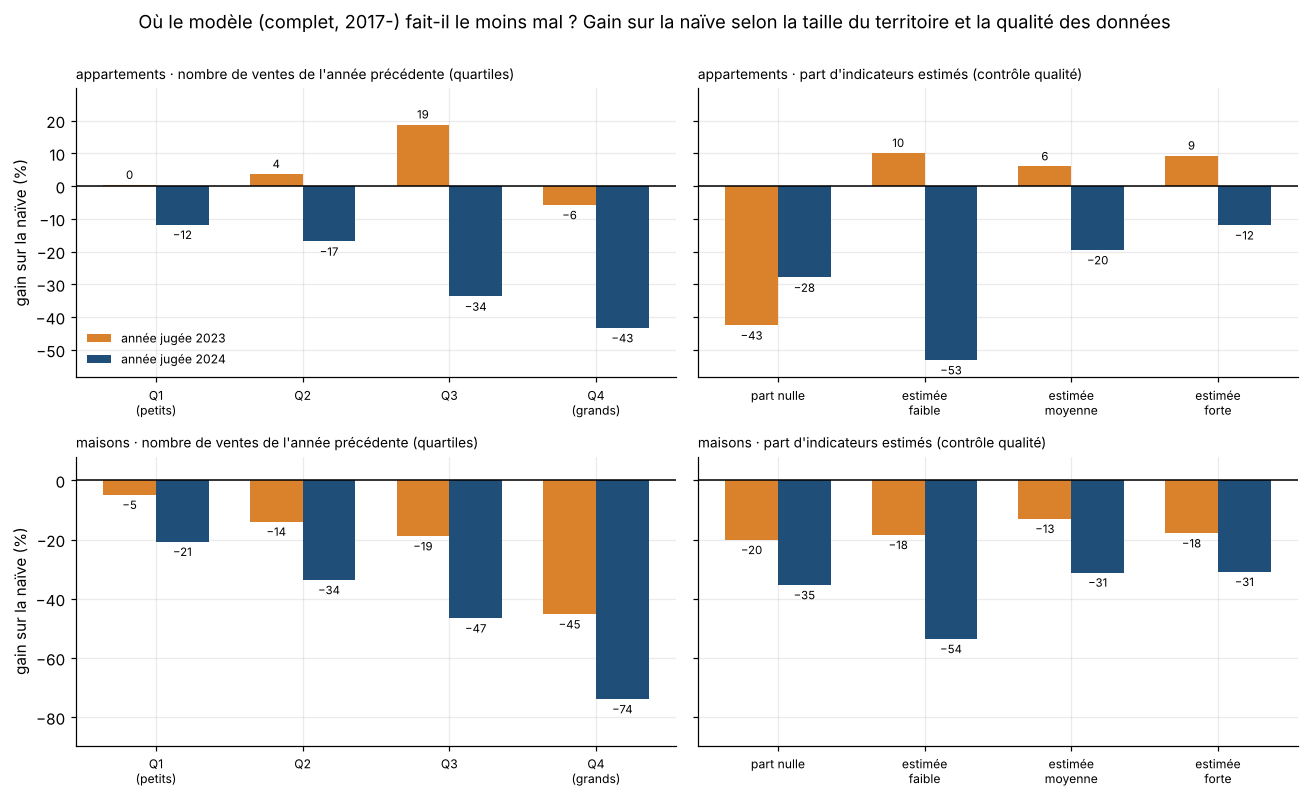

gain sur la naïve (%)       territoires  \
année jugée                                           2023  2024        2023   
type de bien critère groupe                                                    
appartement  qualité estimée faible                   10.0 -53.0       273.0   
                     estimée forte                     9.0 -12.0       273.0   
                     estimée moyenne                   6.0 -20.0       272.0   
                     part nulle                      -43.0 -28.0        43.0   
             taille  Q1 (petits)                       0.0 -12.0       222.0   
                     Q2                                4.0 -17.0       211.0   
                     Q3                               19.0 -34.0       213.0   
                     Q4 (grands)                      -6.0 -43.0       215.0   
maison       qualité estimée faible                  -18.0 -54.0       587.0   
                     estimée forte                   -18.0 -31.0       586.0   
                     estimée moyenne                 -13.0 -31.0       585.0   
                     part nulle                      -20.0 -35.0        22.0   
             taille  Q1 (petits)                      -5.0 -21.0       445.0   
                     Q2                              -14.0 -34.0       447.0   
                     Q3                              -19.0 -47.0       443.0   
                     Q4 (grands)                     -45.0 -74.0       445.0   

                                             
année jugée                            2024  
type de bien critère groupe                  
appartement  qualité estimée faible   259.0  
                     estimée forte    259.0  
                     estimée moyenne  258.0  
                     part nulle        47.0  
             taille  Q1 (petits)      209.0  
                     Q2               203.0  
                     Q3               205.0  
                     Q4 (grands)      206.0  
maison       qualité estimée faible   585.0  
                     estimée forte    585.0  
                     estimée moyenne  585.0  
                     part nulle        21.0  
             taille  Q1 (petits)      447.0  
                     Q2               447.0  
                     Q3               438.0  
                     Q4 (grands)      444.0

In [24]:
def groupes_ventes(e):
    return pd.qcut(e["nb_ventes_n1"], 4, labels=["Q1\n(petits)", "Q2", "Q3", "Q4\n(grands)"])


def groupes_qualite(e):
    v = e["part_indicateurs_estimes"]
    g = pd.Series("part nulle", index=e.index)
    pos = v > 0
    g[pos] = pd.qcut(v[pos], 3, labels=["estimée\nfaible", "estimée\nmoyenne", "estimée\nforte"]).astype(str)
    return g


ordre_v = ["Q1\n(petits)", "Q2", "Q3", "Q4\n(grands)"]
ordre_q = ["part nulle", "estimée\nfaible", "estimée\nmoyenne", "estimée\nforte"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), sharey="row")
rows = []
for i, tb in enumerate(TYPES):
    for k, (nomg, fg, ordre_g, titre) in enumerate([("taille", groupes_ventes, ordre_v, "nombre de ventes de l'année précédente (quartiles)"),
                                                     ("qualité", groupes_qualite, ordre_q, "part d'indicateurs estimés (contrôle qualité)")]):
        ax = axes[i, k]
        larg = 0.36
        for q, (a, c_) in enumerate(zip(ANNEES, [ORANGE, BLEU])):
            e = sel(a, tb)
            g = fg(e).astype(str)
            prev = previsions[("prix N-1 + territoire", 2017, a)].loc[e.index]
            vals = []
            for o in ordre_g:
                m = (g == o).to_numpy()
                mae, mn = (prev[m] - e[CIBLE][m]).abs().mean(), (e["prix_n1"][m] - e[CIBLE][m]).abs().mean()
                vals.append((1 - mae / mn) * 100)
                rows.append({"type de bien": tb, "critère": nomg, "groupe": o.replace("\n", " "), "année jugée": a, "gain sur la naïve (%)": vals[-1], "territoires": int(m.sum())})
            x = np.arange(len(ordre_g)) + (q - 0.5) * larg
            ax.bar(x, vals, width=larg, color=c_, label=f"année jugée {a}")
            for xi, vi in zip(x, vals):
                ax.text(xi, vi + (1 if vi >= 0 else -1), f"{vi:.0f}".replace("-", "−"), ha="center", va="bottom" if vi >= 0 else "top", fontsize=7.5)
        ax.axhline(0, color="black", lw=1)
        ax.set_xticks(np.arange(len(ordre_g)))
        ax.set_xticklabels(ordre_g, fontsize=8)
        ax.set_title(f"{tb}s · {titre}", loc="left", fontsize=9)
        ax.set_ylim(ax.get_ylim()[0] - 6, ax.get_ylim()[1] + 4)
        if k == 0:
            ax.set_ylabel("gain sur la naïve (%)")
        if i == 0 and k == 0:
            ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Où le modèle (complet, 2017-) fait-il le moins mal ? Gain sur la naïve selon la taille du territoire et la qualité des données", y=1.0)
fig.tight_layout()
plt.show()
ou = pd.DataFrame(rows)
ou.pivot_table(index=["type de bien", "critère", "groupe"], columns="année jugée", values=["gain sur la naïve (%)", "territoires"]).round(0)

In [25]:
tq = ou[(ou["critère"] == "taille") & (ou["année jugée"] == 2024)].set_index(["type de bien", "groupe"])["gain sur la naïve (%)"]
nn = ou[(ou["critère"] == "qualité") & (ou["groupe"] == "part nulle") & (ou["année jugée"] == 2024)].set_index("type de bien")["territoires"]
t23 = ou[(ou["critère"] == "taille") & (ou["année jugée"] == 2023) & (ou["type de bien"] == "appartement")]["gain sur la naïve (%)"]
lecture(f"En 2024, le modèle fait le moins mal dans les petits territoires : la perte va de {fr(tq[('appartement', 'Q1 (petits)')], 0, True)} % (Q1, petits) à "
        f"{fr(tq[('appartement', 'Q4 (grands)')], 0, True)} % (Q4, grands) pour les appartements, et de {fr(tq[('maison', 'Q1 (petits)')], 0, True)} % à "
        f"{fr(tq[('maison', 'Q4 (grands)')], 0, True)} % pour les maisons. C'est l'attente de la feuille de route (gain surtout dans les petits territoires), sans que le gain devienne positif en 2024. "
        f"En 2023 le motif est moins net pour les appartements (de {fr(t23.min(), 0, True)} % à {fr(t23.max(), 0, True)} % selon le quartile, sans ordre régulier). "
        f"Le contrôle qualité ne montre pas de tendance nette ; le groupe « part nulle » ne compte que {int(nn['appartement'])} appartements et {int(nn['maison'])} maisons : ses barres sont peu fiables.")

**Lecture.** En 2024, le modèle fait le moins mal dans les petits territoires : la perte va de −12 % (Q1, petits) à −43 % (Q4, grands) pour les appartements, et de −21 % à −74 % pour les maisons. C'est l'attente de la feuille de route (gain surtout dans les petits territoires), sans que le gain devienne positif en 2024. En 2023 le motif est moins net pour les appartements (de −6 % à +19 % selon le quartile, sans ordre régulier). Le contrôle qualité ne montre pas de tendance nette ; le groupe « part nulle » ne compte que 47 appartements et 21 maisons : ses barres sont peu fiables.

### 4.10 Poids des variables : stabilité des coefficients entre 2020- et 2017-

Coefficients standardisés de l'Elastic Net (modèle complet, fenêtre 2024), hors prix N-1 : un point par variable, deux périodes. Les coefficients sont exprimés pour une variable centrée-réduite et un prix en log : ils se comparent entre eux, pas à des €/m².

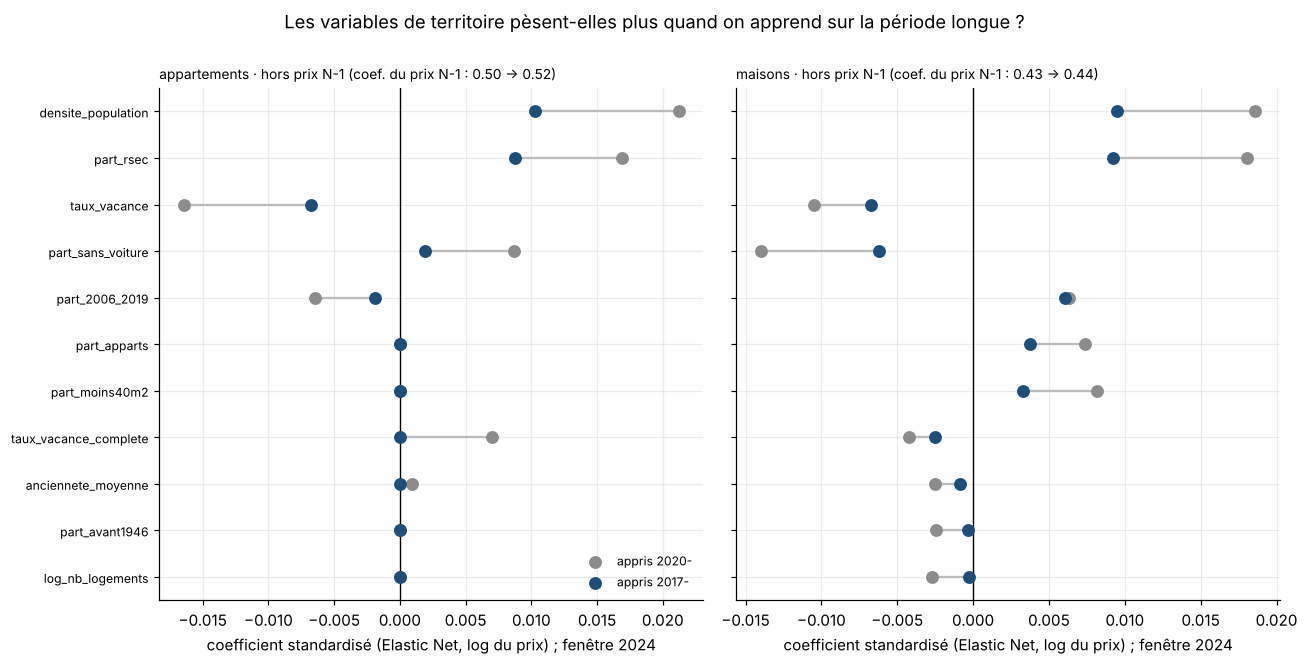

,appartement 2020-,appartement 2017-,maison 2020-,maison 2017-
prix_n1,0.497,0.515,0.434,0.444
taux_vacance,-0.016,-0.007,-0.010,-0.007
part_rsec,0.021,0.010,0.018,0.009
part_apparts,0.000,-0.000,0.007,0.004
log_nb_logements,-0.000,-0.000,-0.003,-0.000
part_moins40m2,0.007,0.000,0.008,0.003
part_avant1946,0.001,0.000,-0.002,-0.000
part_2006_2019,0.009,0.002,0.006,0.006
anciennete_moyenne,-0.000,-0.000,-0.002,-0.001
part_sans_voiture,-0.000,-0.000,-0.014,-0.006


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
autres = [v for v in MODELE_COMPLET if v != "prix_n1"]
for ax, tb in zip(axes, TYPES):
    c20, c17 = coefs_std[("prix N-1 + territoire", 2020, 2024, tb)], coefs_std[("prix N-1 + territoire", 2017, 2024, tb)]
    ordre_c = c17[autres].abs().sort_values().index.tolist()
    y = np.arange(len(ordre_c))
    for yi, v in zip(y, ordre_c):
        ax.plot([c20[v], c17[v]], [yi, yi], color="#bbb", lw=1.5, zorder=1)
    ax.scatter([c20[v] for v in ordre_c], y, color=GRIS, s=55, zorder=3, label="appris 2020-")
    ax.scatter([c17[v] for v in ordre_c], y, color=BLEU, s=55, zorder=4, label="appris 2017-")
    ax.axvline(0, color="black", lw=0.9)
    ax.set_yticks(y)
    ax.set_yticklabels(ordre_c, fontsize=8)
    ax.set_xlabel("coefficient standardisé (Elastic Net, log du prix) ; fenêtre 2024")
    ax.set_title(f"{tb}s · hors prix N-1 (coef. du prix N-1 : {c20['prix_n1']:.2f} → {c17['prix_n1']:.2f})", loc="left", fontsize=9)
    if tb == "appartement":
        ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Les variables de territoire pèsent-elles plus quand on apprend sur la période longue ?", y=1.0)
fig.tight_layout()
plt.show()
cf_tab = pd.DataFrame({f"{tb} {d_}-": coefs_std[("prix N-1 + territoire", d_, 2024, tb)] for tb in TYPES for d_ in (2020, 2017)})
cf_tab.round(3)

In [27]:
cA20, cA17 = coefs_std[("prix N-1 + territoire", 2020, 2024, "appartement")], coefs_std[("prix N-1 + territoire", 2017, 2024, "appartement")]
cM20, cM17 = coefs_std[("prix N-1 + territoire", 2020, 2024, "maison")], coefs_std[("prix N-1 + territoire", 2017, 2024, "maison")]
n_moins = int(sum((abs(c17[autres]) <= abs(c20[autres]) + 1e-9).sum() for c20, c17 in [(cA20, cA17), (cM20, cM17)]))
n_tot = 2 * len(autres)
lecture(f"Les variables de territoire pèsent **moins** sur la période longue, pas plus : {n_moins} coefficients sur {n_tot} sont plus petits ou égaux en valeur absolue. "
        f"Par exemple `densite_population` passe de {fr(cA20['densite_population'], 3, True)} à {fr(cA17['densite_population'], 3, True)} (appartements) et de {fr(cM20['densite_population'], 3, True)} à {fr(cM17['densite_population'], 3, True)} (maisons) ; "
        f"`taux_vacance` de {fr(cA20['taux_vacance'], 3, True)} à {fr(cA17['taux_vacance'], 3, True)} (appartements). "
        f"Tous restent très petits (au plus {fr(max(cA20[autres].abs().max(), cA17[autres].abs().max(), cM20[autres].abs().max(), cM17[autres].abs().max()), 3)}) face au prix N-1 "
        f"({fr(cA17['prix_n1'], 2)} pour les appartements, {fr(cM17['prix_n1'], 2)} pour les maisons, en 2017-). "
        "Avec la période longue, le modèle s'appuie encore davantage sur le prix N-1 : la baisse d'erreur ne vient pas des variables de territoire.")

**Lecture.** Les variables de territoire pèsent **moins** sur la période longue, pas plus : 22 coefficients sur 22 sont plus petits ou égaux en valeur absolue. Par exemple `densite_population` passe de +0,017 à +0,009 (appartements) et de +0,019 à +0,010 (maisons) ; `taux_vacance` de −0,016 à −0,007 (appartements). Tous restent très petits (au plus 0,021) face au prix N-1 (0,52 pour les appartements, 0,44 pour les maisons, en 2017-). Avec la période longue, le modèle s'appuie encore davantage sur le prix N-1 : la baisse d'erreur ne vient pas des variables de territoire.

### 4.11 Coefficient du prix N-1 et réglage

Dans une régression log-log, un coefficient de 1 signifie « le prix de cette année est proportionnel à celui de l'an dernier » : c'est la structure de la naïve. Un coefficient sous 1 tire les territoires chers vers la moyenne. La pente MCO (sans pénalisation) de « prix N-1 seul » est la mesure directe ; les coefficients de l'Elastic Net sont un peu rétrécis par la pénalisation, et ceux du modèle complet sont à lire avec les autres variables présentes.

In [28]:
principal_r = reglages[reglages["début"].isin([2017, 2020])]
coef_tab = principal_r.pivot_table(index=["type de bien", "année jugée", "modèle"], columns="début", values="coef. prix N-1")
coef_tab.columns = [f"coef. appris {c}-" for c in coef_tab.columns]
mco = principal_r[principal_r["modèle"] == "prix N-1 seul"].pivot_table(index=["type de bien", "année jugée"], columns="début", values="pente MCO")
mco.columns = [f"pente MCO appris {c}-" for c in mco.columns]
coef_tab.round(3).join(mco.assign(modèle="prix N-1 seul").set_index("modèle", append=True).round(3), how="left")

coef. appris 2017-  \
type de bien année jugée modèle                                      
appartement  2023        prix N-1 + territoire               0.974   
                         prix N-1 seul                       0.997   
             2024        prix N-1 + territoire               0.968   
                         prix N-1 seul                       0.994   
maison       2023        prix N-1 + territoire               0.990   
                         prix N-1 seul                       1.015   
             2024        prix N-1 + territoire               0.966   
                         prix N-1 seul                       1.008   

                                                coef. appris 2020-  \
type de bien année jugée modèle                                      
appartement  2023        prix N-1 + territoire               0.948   
                         prix N-1 seul                       0.972   
             2024        prix N-1 + territoire               0.919   
                         prix N-1 seul                       0.966   
maison       2023        prix N-1 + territoire               0.963   
                         prix N-1 seul                       1.008   
             2024        prix N-1 + territoire               0.922   
                         prix N-1 seul                       0.994   

                                                pente MCO appris 2017-  \
type de bien année jugée modèle                                          
appartement  2023        prix N-1 + territoire                     NaN   
                         prix N-1 seul                           0.997   
             2024        prix N-1 + territoire                     NaN   
                         prix N-1 seul                           0.994   
maison       2023        prix N-1 + territoire                     NaN   
                         prix N-1 seul                           1.015   
             2024        prix N-1 + territoire                     NaN   
                         prix N-1 seul                           1.008   

                                                pente MCO appris 2020-  
type de bien année jugée modèle                                         
appartement  2023        prix N-1 + territoire                     NaN  
                         prix N-1 seul                           0.986  
             2024        prix N-1 + territoire                     NaN  
                         prix N-1 seul                           0.982  
maison       2023        prix N-1 + territoire                     NaN  
                         prix N-1 seul                           1.008  
             2024        prix N-1 + territoire                     NaN  
                         prix N-1 seul                           0.997

In [29]:
principal_r.pivot_table(index=["type de bien", "année jugée", "modèle"], columns="début", values=["alpha", "l1_ratio", "lignes d'apprentissage"]).round(5)

alpha          l1_ratio  \
début                                              2017     2020     2017   
type de bien année jugée modèle                                             
appartement  2023        prix N-1 + territoire  0.00316  0.00316      0.8   
                         prix N-1 seul          0.00001  0.01000      0.2   
             2024        prix N-1 + territoire  0.00316  0.01000      0.8   
                         prix N-1 seul          0.00001  0.01000      0.2   
maison       2023        prix N-1 + territoire  0.00100  0.00100      0.8   
                         prix N-1 seul          0.00001  0.00001      0.2   
             2024        prix N-1 + territoire  0.00032  0.00032      0.8   
                         prix N-1 seul          0.00001  0.00316      0.2   

                                                    lignes d'apprentissage  \
début                                          2020                   2017   
type de bien année jugée modèle                                              
appartement  2023        prix N-1 + territoire  0.8                 4972.0   
                         prix N-1 seul          0.5                 4972.0   
             2024        prix N-1 + territoire  0.2                 5833.0   
                         prix N-1 seul          0.8                 5833.0   
maison       2023        prix N-1 + territoire  0.8                10673.0   
                         prix N-1 seul          0.2                10673.0   
             2024        prix N-1 + territoire  0.8                12453.0   
                         prix N-1 seul          0.2                12453.0   

                                                        
début                                             2020  
type de bien année jugée modèle                         
appartement  2023        prix N-1 + territoire  2647.0  
                         prix N-1 seul          2647.0  
             2024        prix N-1 + territoire  3508.0  
                         prix N-1 seul          3508.0  
maison       2023        prix N-1 + territoire  5340.0  
                         prix N-1 seul          5340.0  
             2024        prix N-1 + territoire  7120.0  
                         prix N-1 seul          7120.0

In [30]:
pm = principal_r[principal_r["modèle"] == "prix N-1 seul"].pivot_table(index=["type de bien", "année jugée"], columns="début", values="pente MCO")
pc = principal_r[principal_r["modèle"] == "prix N-1 + territoire"].pivot_table(index=["type de bien", "année jugée"], columns="début", values="coef. prix N-1")
a_min = principal_r[principal_r["modèle"] == "prix N-1 seul"]["alpha"].min()
n_bord = int((principal_r[principal_r["modèle"] == "prix N-1 seul"]["alpha"] <= GRILLE_EN["alpha"][0] + 1e-12).sum())
lecture(f"Le coefficient du prix N-1 se rapproche de 1 avec la période longue : pente MCO de « prix N-1 seul » de {fr(pm.loc[('appartement', 2024), 2020], 3)} à {fr(pm.loc[('appartement', 2024), 2017], 3)} (appartements 2024) "
        f"et de {fr(pm.loc[('maison', 2024), 2020], 3)} à {fr(pm.loc[('maison', 2024), 2017], 3)} (maisons 2024) ; modèle complet de {fr(pc.loc[('appartement', 2024), 2020], 2)} à {fr(pc.loc[('appartement', 2024), 2017], 2)} (appartements 2024). "
        f"Plus le coefficient est proche de 1, plus le modèle ressemble à la naïve. Le réglage de « prix N-1 seul » retient le plus petit alpha de la grille ({a_min:.0e}) dans {n_bord} cas sur {len(principal_r[principal_r['modèle'] == 'prix N-1 seul'])} : "
        "avec une seule variable, la pénalité ne sert à rien et le modèle équivaut à la régression linéaire ; ce bord de grille n'est pas un défaut à corriger.")

**Lecture.** Le coefficient du prix N-1 se rapproche de 1 avec la période longue : pente MCO de « prix N-1 seul » de 0,982 à 0,994 (appartements 2024) et de 0,997 à 1,008 (maisons 2024) ; modèle complet de 0,92 à 0,97 (appartements 2024). Plus le coefficient est proche de 1, plus le modèle ressemble à la naïve. Le réglage de « prix N-1 seul » retient le plus petit alpha de la grille (1e-05) dans 5 cas sur 8 : avec une seule variable, la pénalité ne sert à rien et le modèle équivaut à la régression linéaire ; ce bord de grille n'est pas un défaut à corriger.

### 4.12 Erreur en pratique : part des territoires sous un seuil d'erreur

Courbes cumulées de l'erreur absolue par territoire (modèle complet et naïve). Une courbe plus haute et plus à gauche est meilleure : elle atteint plus tôt une grande part des territoires.

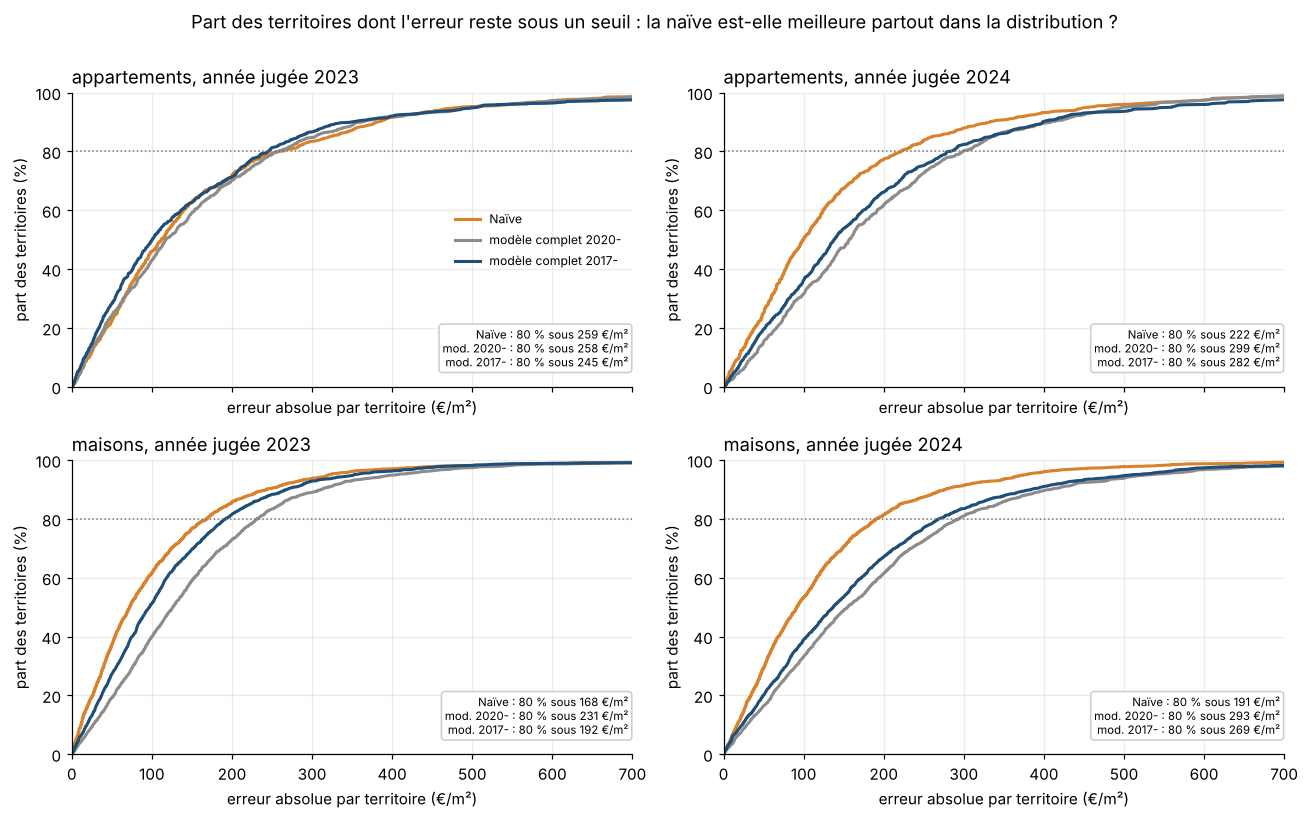

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4), sharex=True)
q80 = {}
for i, tb in enumerate(TYPES):
    for j, a in enumerate(ANNEES):
        ax = axes[i, j]
        e = sel(a, tb)
        series = [("Naïve", ORANGE, (e["prix_n1"] - e[CIBLE]).abs()),
                  ("modèle complet 2020-", GRIS, (previsions[("prix N-1 + territoire", 2020, a)].loc[e.index] - e[CIBLE]).abs()),
                  ("modèle complet 2017-", BLEU, (previsions[("prix N-1 + territoire", 2017, a)].loc[e.index] - e[CIBLE]).abs())]
        txt = []
        for nom, c_, err in series:
            s = np.sort(err.to_numpy())
            ax.plot(s, np.arange(1, len(s) + 1) / len(s) * 100, color=c_, lw=2, label=nom)
            q80[(tb, a, nom)] = np.percentile(s, 80)
            txt.append(f"{nom.replace('modèle complet', 'mod.')} : 80 % sous {np.percentile(s, 80):.0f} €/m²")
        ax.axhline(80, color="#777", ls=":", lw=1)
        ax.set_xlim(0, 700)
        ax.set_ylim(0, 100)
        ax.set_xlabel("erreur absolue par territoire (€/m²)")
        ax.set_ylabel("part des territoires (%)")
        ax.set_title(f"{tb}s, année jugée {a}", loc="left")
        ax.text(695, 6, "\n".join(txt), ha="right", va="bottom", fontsize=7.5, bbox=dict(boxstyle="round", fc="white", ec="#ccc"))
        if i == 0 and j == 0:
            ax.legend(frameon=False, fontsize=8, loc="center right")
fig.suptitle("Part des territoires dont l'erreur reste sous un seuil : la naïve est-elle meilleure partout dans la distribution ?", y=1.0)
fig.tight_layout()
plt.show()

In [32]:
lecture(f"En 2024, la naïve est meilleure sur toute la distribution, pas seulement en moyenne : pour 80 % des appartements, son erreur est sous {fr(q80[('appartement', 2024, 'Naïve')], 0)} €/m², "
        f"contre {fr(q80[('appartement', 2024, 'modèle complet 2020-')], 0)} (2020-) et {fr(q80[('appartement', 2024, 'modèle complet 2017-')], 0)} (2017-) pour le modèle complet ; pour les maisons, "
        f"{fr(q80[('maison', 2024, 'Naïve')], 0)} contre {fr(q80[('maison', 2024, 'modèle complet 2020-')], 0)} et {fr(q80[('maison', 2024, 'modèle complet 2017-')], 0)}. "
        f"En 2023, pour les appartements, les trois courbes sont presque confondues et le modèle 2017- passe même sous la naïve au seuil de 80 % ({fr(q80[('appartement', 2023, 'modèle complet 2017-')], 0)} contre {fr(q80[('appartement', 2023, 'Naïve')], 0)} €/m²).")

**Lecture.** En 2024, la naïve est meilleure sur toute la distribution, pas seulement en moyenne : pour 80 % des appartements, son erreur est sous 222 €/m², contre 299 (2020-) et 282 (2017-) pour le modèle complet ; pour les maisons, 191 contre 293 et 269. En 2023, pour les appartements, les trois courbes sont presque confondues et le modèle 2017- passe même sous la naïve au seuil de 80 % (245 contre 259 €/m²).

## 5. Conclusion

In [33]:
cc = "prix N-1 + territoire"
bi = mesures[(mesures["modèle"] == cc) & (mesures["année jugée"] == 2024)].pivot_table(index="type de bien", columns="début", values="biais")
xA = ecarts_periode[(ecarts_periode["type de bien"] == "appartement")]
display(Markdown(f"""
**Question de H4** : apprendre sur la période longue réduit-il le biais de 2024 et rend-il les variables de territoire plus utiles ?

1. **Biais et MAE** (4.1, 4.2) : la période longue fait baisser la MAE dans {n_baisse} cas sur {len(gains)}. Le biais de 2024 du modèle complet passe de {fr(bi.loc['appartement', 2020], 0, True)} à {fr(bi.loc['appartement', 2017], 0, True)} €/m² (appartements) et de {fr(bi.loc['maison', 2020], 0, True)} à {fr(bi.loc['maison', 2017], 0, True)} (maisons) : il reste positif. L'écart avec 2020- est net pour les maisons ({nm} cas sur 4), non concluant pour les appartements ({na} cas net sur 4).
2. **D'où vient le gain** (4.4, 4.5) : de la part commune, c'est-à-dire du biais, pas de la part propre. La période longue corrige le « quand » en partie, pas le « où ».
3. **Contre la naïve** (4.3, 4.12) : sur {len(t)} scénarios, {n_bat} satisfont la règle 1.5 (intervalle de confiance entièrement sous 0). En 2024, le modèle ne fait mieux que la naïve que dans {fr(p24.min(), 0)} % à {fr(p24.max(), 0)} % des territoires.
4. **Variables de territoire** (4.7, 4.10) : elles **n'aident pas davantage** sur la période longue. Leurs coefficients diminuent ({n_moins} sur {n_tot} plus petits ou égaux) et, pour les maisons, le classement des territoires se dégrade (ρ de {fr(rr.loc[('maison', 2024), 2020], 2)} à {fr(rr.loc[('maison', 2024), 2017], 2)} en 2024). Le gain en MAE vient du prix N-1 et du biais.
5. **Phase du marché** (4.8, éclairage hors règle 1.5) : le modèle bat la naïve quand le marché monte ({fr(mont.min(), 0, True)} % à {fr(mont.max(), 0, True)} % en 2021-2022) et perd quand il se retourne (2024). L'échec de 2024 est celui d'un retournement, pas d'un défaut général.
6. **Où** (4.9) : le modèle fait le moins mal dans les petits territoires.
7. **Coefficient du prix N-1** (4.11) : plus proche de 1 avec la période longue.

**Décision** : le modèle pont retenu pour la suite du tour 2 est le **modèle complet appris sur la période longue (2017-)**. Il fait mieux que le niveau 1 sans battre la naïve : H4 donne une base de départ, pas un modèle gagnant. Les prochaines hypothèses doivent apporter ce que H4 ne donne pas : une information sur la phase du marché (le « quand »).

**Limites à déclarer**
- Les photos fixes (recensement 2022, équipements 2025, Filosofi, LOVAC) s'appliquent aussi aux prix 2017-2019 : pour ces années, on utilise une information plus récente que les prix. Prévu par la feuille de route (P6).
- Deux années jugées seulement (2023 et 2024) dans la règle de décision : un retournement de marché pèse beaucoup sur chaque résultat. Les années 2021 et 2022 de la section 4.8 sont un éclairage.
- Le biais de la naïve change de signe d'une année à l'autre (négatif en 2023, positif en 2024) : la comparaison des biais se lit année par année.
- Le réglage de « prix N-1 seul » retient le plus petit alpha de la grille dans {n_bord} cas sur 8 : avec une seule variable, le modèle équivaut à la régression linéaire.
- Le groupe « part nulle » du contrôle qualité (4.9) est petit (quelques dizaines de territoires) : ses résultats sont peu fiables.

Le test 2025 n'est pas ouvert ici : il est réservé au modèle retenu à la fin du niveau 2.
"""))


**Question de H4** : apprendre sur la période longue réduit-il le biais de 2024 et rend-il les variables de territoire plus utiles ?

1. **Biais et MAE** (4.1, 4.2) : la période longue fait baisser la MAE dans 8 cas sur 8. Le biais de 2024 du modèle complet passe de +150 à +136 €/m² (appartements) et de +174 à +151 (maisons) : il reste positif. L'écart avec 2020- est net pour les maisons (4 cas sur 4), non concluant pour les appartements (0 cas net sur 4).
2. **D'où vient le gain** (4.4, 4.5) : de la part commune, c'est-à-dire du biais, pas de la part propre. La période longue corrige le « quand » en partie, pas le « où ».
3. **Contre la naïve** (4.3, 4.12) : sur 16 scénarios, 0 satisfont la règle 1.5 (intervalle de confiance entièrement sous 0). En 2024, le modèle ne fait mieux que la naïve que dans 18 % à 30 % des territoires.
4. **Variables de territoire** (4.7, 4.10) : elles **n'aident pas davantage** sur la période longue. Leurs coefficients diminuent (22 sur 22 plus petits ou égaux) et, pour les maisons, le classement des territoires se dégrade (ρ de 0,18 à 0,03 en 2024). Le gain en MAE vient du prix N-1 et du biais.
5. **Phase du marché** (4.8, éclairage hors règle 1.5) : le modèle bat la naïve quand le marché monte (+16 % à +32 % en 2021-2022) et perd quand il se retourne (2024). L'échec de 2024 est celui d'un retournement, pas d'un défaut général.
6. **Où** (4.9) : le modèle fait le moins mal dans les petits territoires.
7. **Coefficient du prix N-1** (4.11) : plus proche de 1 avec la période longue.

**Décision** : le modèle pont retenu pour la suite du tour 2 est le **modèle complet appris sur la période longue (2017-)**. Il fait mieux que le niveau 1 sans battre la naïve : H4 donne une base de départ, pas un modèle gagnant. Les prochaines hypothèses doivent apporter ce que H4 ne donne pas : une information sur la phase du marché (le « quand »).

**Limites à déclarer**
- Les photos fixes (recensement 2022, équipements 2025, Filosofi, LOVAC) s'appliquent aussi aux prix 2017-2019 : pour ces années, on utilise une information plus récente que les prix. Prévu par la feuille de route (P6).
- Deux années jugées seulement (2023 et 2024) dans la règle de décision : un retournement de marché pèse beaucoup sur chaque résultat. Les années 2021 et 2022 de la section 4.8 sont un éclairage.
- Le biais de la naïve change de signe d'une année à l'autre (négatif en 2023, positif en 2024) : la comparaison des biais se lit année par année.
- Le réglage de « prix N-1 seul » retient le plus petit alpha de la grille dans 5 cas sur 8 : avec une seule variable, le modèle équivaut à la régression linéaire.
- Le groupe « part nulle » du contrôle qualité (4.9) est petit (quelques dizaines de territoires) : ses résultats sont peu fiables.

Le test 2025 n'est pas ouvert ici : il est réservé au modèle retenu à la fin du niveau 2.
